# Clean up the fulltext results from the new method

This Notebook is modified from the version that was used to clean up the larger-scale data (abstracts only) to assure the results are comparable. Not necessarily all findings are similar in the fulltext data which only includes texts from years 2016-2026.

----------

This Notebook aims to remove the sentences that are not valid for one reason or another. These reasons include at least the following:
- entity does not refer to the correct target entity, e.g. "HE" as in Higher Education, not as pronoun, or "US" as in United States, not as pronoun, or "palm" as in palm oil, not as Pathways Language Model, among other examples
- the sentence has less than 3 whitespace-delimited tokens -- these are likely to be titles or boilerplate rather than actual sentences that would give any meaningful information
- the sentence is boilerplate that appears in corpus multiple times
- the original sentence includes `[MASK]` so it hasn't been scored

In [1]:
import pandas as pd
from pathlib import Path
import matplotlib.pyplot as plt
import seaborn as sns
from collections import Counter
from tqdm import tqdm

In [2]:
id_columns = ["paper_id", "source_file", "global_i", "sentence_index", "section", "section_type", "paragraph_index", "sent_id", "match_id"]

In [3]:
dtypes = {
    "year": int,
    "domain": "category",
    "sent_id": int,
    "match_id": int,
    "entity_lower": "category",
    "in_noun_chunk": bool,
    "chunk_root_dep": "category",
    "score": float
}

In [4]:
METADATA_DIR = Path("/scratch/project_2017974/data/xml-fulltexts-extended-metadata/fixed/masked-sentences/")
METADATA_FILES = sorted(METADATA_DIR.iterdir())
df = pd.concat((pd.read_csv(file) for file in METADATA_FILES), ignore_index=True)
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1024545 entries, 0 to 1024544
Data columns (total 21 columns):
 #   Column                   Non-Null Count    Dtype 
---  ------                   --------------    ----- 
 0   paper_id                 1024545 non-null  object
 1   year                     1024545 non-null  int64 
 2   domain                   1024545 non-null  object
 3   source_file              1024545 non-null  object
 4   global_i                 1024545 non-null  int64 
 5   sentence_index           1024545 non-null  int64 
 6   section                  957375 non-null   object
 7   section_type             1024545 non-null  object
 8   paragraph_index          1024545 non-null  int64 
 9   sent_id                  1024545 non-null  int64 
 10  match_id                 1024545 non-null  int64 
 11  sentence                 1024545 non-null  object
 12  masked_sentence_minimal  1024545 non-null  object
 13  masked_sentence_chunk    1024545 non-null  object
 14  en

In [6]:
# If all scores have already been written to a single file, upload from that
INTERMEDIATE_SAVE_PATH = "/scratch/project_2017974/data/intermediate-files/xml-fulltexts-extended.csv"
scores = pd.read_csv(INTERMEDIATE_SAVE_PATH, dtype=dtypes)

In [7]:
scores.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1024545 entries, 0 to 1024544
Data columns (total 20 columns):
 #   Column                   Non-Null Count    Dtype   
---  ------                   --------------    -----   
 0   paper_id                 1024545 non-null  object  
 1   year                     1024545 non-null  int64   
 2   domain                   1024545 non-null  category
 3   sentence                 1024545 non-null  object  
 4   masked_sentence_minimal  1024545 non-null  object  
 5   masked_sentence_chunk    1024545 non-null  object  
 6   entity                   1024545 non-null  object  
 7   entity_lower             1024545 non-null  category
 8   in_noun_chunk            1024545 non-null  bool    
 9   chunk_text               994161 non-null   object  
 10  chunk_root_text          994158 non-null   object  
 11  chunk_root_dep           994161 non-null   category
 12  head                     994161 non-null   object  
 13  score                    10

In [8]:
df.iloc[707307]

paper_id                                                         W3113178743
year                                                                    2020
domain                                                       Health Sciences
source_file                            fulltext-sentences-extended_007.spacy
global_i                                                               89153
sentence_index                                                             0
section                                                              Results
section_type                                                            body
paragraph_index                                                           11
sent_id                                                                    0
match_id                                                                   2
sentence                   Because implemented AI models are required to ...
masked_sentence_minimal    Because implemented AI models are required to ...

In [9]:
scores.iloc[707307]

paper_id                                                         W3113178743
year                                                                    2020
domain                                                       Health Sciences
sentence                   Because implemented AI models are required to ...
masked_sentence_minimal    Because implemented AI models are required to ...
masked_sentence_chunk      Because implemented AI models are required to ...
entity                                                                models
entity_lower                                                          models
in_noun_chunk                                                           True
chunk_text                                                      these models
chunk_root_text                                                       models
chunk_root_dep                                                     nsubjpass
head                                                                evaluate

In [10]:
df["score"] = scores["score"]

In [6]:
df = df.fillna(value={"section": "[MISSING]"})

In [11]:
# Get the extended token annotations
TOKEN_DIR = Path("/scratch/project_2017974/data/xml-fulltexts-extended-metadata/fixed/token-data")
TOKEN_FILES = sorted(TOKEN_DIR.iterdir())

In [12]:
token_dtypes = {key: "category" for key in "domain,role,pos,tag,dep,ent_type,ent_iob".split(",")}
token_df = pd.concat((pd.read_csv(f) for f in TOKEN_FILES), ignore_index=True)
token_df = token_df.astype(token_dtypes)
token_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3500886 entries, 0 to 3500885
Data columns (total 19 columns):
 #   Column           Dtype   
---  ------           -----   
 0   paper_id         object  
 1   year             int64   
 2   domain           category
 3   source_file      object  
 4   global_i         int64   
 5   sentence_index   int64   
 6   section          object  
 7   section_type     object  
 8   paragraph_index  int64   
 9   sent_id          int64   
 10  match_id         int64   
 11  role             category
 12  token_i          int64   
 13  text             object  
 14  pos              category
 15  tag              category
 16  dep              category
 17  ent_type         category
 18  ent_iob          category
dtypes: category(7), int64(7), object(5)
memory usage: 343.9+ MB


In [13]:
token_df.paper_id.nunique()

4925

In [14]:
df.paper_id.nunique()

4925

In [21]:
token_df = token_df.fillna(value={"section": "[MISSING]"})

In [15]:
len(df.drop_duplicates(id_columns))

1024545

In [16]:
len(token_df.drop_duplicates(id_columns))

2018706

In [17]:
len(df[df.duplicated(id_columns, keep=False)])

0

In [18]:
match_df = token_df[token_df["role"] == "match"]
len(match_df[match_df.duplicated(id_columns+["token_i"], keep=False)])

0

In [19]:
len(match_df[match_df.duplicated(id_columns, keep=False)])

61451

The goal is to merge the sentences and scores with the match token metadata, but due to insufficient indexing, the existing id columns are not enough to distinguish between the correct rows. The problems in merging include at least the following:
- if the entity is not in noun chunk, it only has rows tagged with "match" in the token metadata --> cannot reliably detect the boundaries by just looking at when the role changes
- the "text" in the token metadata is the full token parsed with spaCy, and it is not necessarily a subset of the entity (e.g. entity might be "AI", but the regex was \bai\b and has matched something like Claude.ai)
- multi-word entites are split into multiple rows in the token data, but they correspond to only one row in sentence/score data

In [21]:
merged = df.merge(match_df, on=id_columns, how="left")
merged.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1057410 entries, 0 to 1057409
Data columns (total 32 columns):
 #   Column                   Non-Null Count    Dtype   
---  ------                   --------------    -----   
 0   paper_id                 1057410 non-null  object  
 1   year_x                   1057410 non-null  int64   
 2   domain_x                 1057410 non-null  object  
 3   source_file              1057410 non-null  object  
 4   global_i                 1057410 non-null  int64   
 5   sentence_index           1057410 non-null  int64   
 6   section                  984481 non-null   object  
 7   section_type             1057410 non-null  object  
 8   paragraph_index          1057410 non-null  int64   
 9   sent_id                  1057410 non-null  int64   
 10  match_id                 1057410 non-null  int64   
 11  sentence                 1057410 non-null  object  
 12  masked_sentence_minimal  1057410 non-null  object  
 13  masked_sentence_chunk    10

In [32]:
len(merged) / len(df)

1.0320776539829877

In [ ]:
merged = merged.rename(columns={"text": "token_text"})

In [46]:
preview_cols = ["paper_id", "global_i", "section", "section_type", "sentence", "entity_lower", "token_text", "chunk_text", "pos", "dep"]

In [27]:
merged[preview_cols].head(20)

,paper_id,global_i,section,section_type,sentence,entity_lower,text,chunk_text,pos,dep
0,W169306565,1,NaN,abstract,Artificial Intelligence (AI) has rapidly becom...,artificial intelligence,Artificial,Artificial Intelligence,PROPN,compound
1,W169306565,1,NaN,abstract,Artificial Intelligence (AI) has rapidly becom...,artificial intelligence,Intelligence,Artificial Intelligence,PROPN,nsubj
2,W169306565,1,NaN,abstract,Artificial Intelligence (AI) has rapidly becom...,ai,AI,(AI,PROPN,appos
3,W169306565,2,NaN,abstract,"However, the growth of AI also raises concerns...",ai,AI,AI,PROPN,pobj
4,W169306565,3,NaN,abstract,This research paper provides a comprehensive o...,ai,AI,AI,PROPN,pobj
5,W169306565,4,NaN,abstract,"To achieve this goal, a thorough review of exi...",ai,AI,AI,PROPN,pobj
6,W169306565,5,NaN,abstract,"The literature review focused on the economic,...",ai,AI,AI,PROPN,pobj
7,W169306565,6,NaN,abstract,The review found that while AI has the potenti...,ai,AI,AI,PROPN,nsubj
8,W169306565,7,NaN,abstract,The paper also presents a discussion of the im...,ai,AI,AI,PROPN,pobj
9,W169306565,8,NaN,abstract,The analysis found that AI has the potential t...,ai,AI,AI,PROPN,nsubj


In [28]:
merged[preview_cols].tail(20)

,paper_id,global_i,section,section_type,sentence,entity_lower,text,chunk_text,pos,dep
1057390,W7140044697,114888,Limitations,body,"Third, the framework addresses the bachelor's ...",models,models,"(e.g., fine-tuning models",NOUN,appos
1057391,W7140044697,114889,Limitations,body,"Fourth, the rapid pace of AI tool development ...",ai,AI,AI tool development,PROPN,compound
1057392,W7140044697,114890,Limitations,body,The framework is designed to be tool-agnostic ...,framework,framework,The framework,NOUN,nsubjpass
1057393,W7140044697,114891,Conclusion,body,This paper proposed an integrative theoretical...,framework,framework,an integrative theoretical framework,NOUN,dobj
1057394,W7140044697,114891,Conclusion,body,This paper proposed an integrative theoretical...,ai,AI,AI-era designers,PROPN,compound
1057395,W7140044697,114891,Conclusion,body,This paper proposed an integrative theoretical...,ai,AI,generative AI design education research,PROPN,compound
1057396,W7140044697,114892,Conclusion,body,"Regarding RQ1, ICC was operationalised as a fo...",model,model,a four-component model,NOUN,pobj
1057397,W7140044697,114892,Conclusion,body,"Regarding RQ1, ICC was operationalised as a fo...",ai,AI,each incorporating AI-specific descriptors,PROPN,npadvmod
1057398,W7140044697,114893,Conclusion,body,The reflective component was identified as sys...,system,system,NaN,NOUN,npadvmod
1057399,W7140044697,114895,Conclusion,body,"Regarding RQ2, the TPACK framework was adapted...",framework,framework,the TPACK framework,NOUN,nsubjpass


In [34]:
merged[merged["entity"] != merged["text"]]["entity_lower"].nunique()

65

In [36]:
merged[merged["entity"] != merged["text"]]["entity_lower"].value_counts()[lambda x: x > 1000]

entity_lower
artificial intelligence        33148
i                              15992
language model                  8452
language models                 8424
large language models           5853
gpt                             5568
ai                              2709
pre-trained language models     2130
large language model            1629
Name: count, dtype: int64

## Deletion of invalid entities

In [38]:
# Inspect some of the instances of non-uppercase "I", as they are likely
# not referring to "I" as in me
merged[preview_cols][(merged["entity"] != "I") & (merged["entity_lower"] == "i")]

,paper_id,global_i,section,section_type,sentence,entity_lower,text,chunk_text,pos,dep
191,W2353482882,167,The pMSSM and ATLAS SUSY searches,body,where i j is the antisymmetric SU (2) tensor w...,i,i,i,PRON,nsubj
193,W2353482882,175,The pMSSM and ATLAS SUSY searches,body,"In this scheme, one assumes the following: (i)...",i,i,i,NOUN,appos
196,W2353482882,180,The pMSSM and ATLAS SUSY searches,body,After the application of the electroweak symme...,i,i.,2 i.,NOUN,attr
215,W2353482882,220,Decision trees and random forest,body,This process is repeated until the final leaf ...,i,i.e.,", i.e. the node",X,advmod
220,W2353482882,241,Decision trees and random forest,body,Overtraining of a classifier is difficult to e...,i,i.e.,NaN,X,advmod
...,...,...,...,...,...,...,...,...,...,...
1056558,W7128682674,113854,Complementing ASSAY_TYPE annotations in ChEMBL...,body,It should also be complementary to the existin...,i,i.e.,NaN,X,advmod
1056620,W7128682674,113952,Data sets for model training and external vali...,body,The assays were manually annotated with the ex...,i,i.e.,NaN,X,advmod
1057051,W7135057845,114544,Structural equation modelling results,body,"In addition, the squared multiple correlations...",i,i.e.,NaN,X,appos
1057064,W7135057845,114588,Mediation analysis,body,"Specifically, UTAUT constructs (i.e., PE, EE, ...",i,i.e.,"i.e., PE",X,advmod


In [39]:
merged[(merged["entity"] != "I") & (merged["entity_lower"] == "i")]["chunk_text"].nunique()

8502

In [42]:
merged[(merged["entity"] != "I") & (merged["entity_lower"] == "i")]["token_text"].nunique()

404

This reveals that regex `\bI\b` produces many, many invalid matches for `I`. With this, though, one could save the instances of `A.I.` and save as said term.

In [43]:
merged[merged["entity"] == "I"]["token_text"].unique()

array(['I', 'I.', '-I', 'I.A.1.5', 'I.1', 'I.4', 'I.5', 'I.3', 'I.2',
       'I.A.1.8', 'I.A.2', 'I.6', 'I.7', 'I.8', 'I.9', 'I.10', 'I.12',
       'I.A.1.2', 'I.A.2.2', 'I.A.2.3', 'I.A.2.4', 'I.A.2.5', 'I.A.2.6',
       'I.11', 'I.15', 'I.14', 'S.I.P.', 'I[x', 'Li-1•I', 'A.I.', 'I.W.',
       'I.V.K.', 'B.I.M.W.', 'F.I.P.A.', '2020)."I', "2020).'I", 'I(V',
       'I→T', '→I', 'I.T.S', 'I.T', '-I.', 'I.L.', 'M.I.T.',
       'A.I.)-based', 'I{A', 'robot.say("I', 'I-95N', 'I(χ', '×I', 'I.G.',
       'I-1', 'I.P.', 'Fig7.I', 'I-', 'I.V.', 'I(r', 'I.Q.', 'I+D+I',
       'I,-II', 'I.2.0', 'I/00001852', 'I.D.', 'M.I.', 'A.L.I.C.E', 'd(I',
       'H.I', 'Y.I.', 'I.e.', 'T.I.', 'S.I.', 'I.A.', '-"I', 'I(q+∆v',
       'I(q', 'b.*I', 'cogito-"I', 'I.viii.8.17', 'I.G.O.', 'A.I',
       'I.M.S.', "I've", 'Ⅱ-Ⅴ-I', 'Ⅳ-I', 'I(X;Y', 'P(VI|I', '4.I', 'I.a',
       'I.b', 'V(I', 'I]apo', 'A.L.I.C.E.', 'D.I.', 'A.I.-related', 'N.I',
       'N.I.', "I'm", 'd.*I', 'i∈I', 'P(I', 'P(I)|a', '\\"I\'m', 'A&I',


In [47]:
merged[preview_cols][(merged["entity"] == "I") & (merged["token_text"] == "I") & (merged["pos"] != "PRON")]

,paper_id,global_i,section,section_type,sentence,entity_lower,token_text,chunk_text,pos,dep
2247,W2756381707,2659,CRF for Sequence Labeling,body,"For example, in NER task with BIOES annotation...",i,I,I,PROPN,dobj
4097,W2783386352,5011,Counteracting the Displacement Effect I: The P...,body,"when γ M (I) R ≈ γ L (I) W, which is exactly t...",i,I,NaN,NOUN,dep
4098,W2783386352,5011,Counteracting the Displacement Effect I: The P...,body,"when γ M (I) R ≈ γ L (I) W, which is exactly t...",i,I,γ L (I) W,PROPN,nmod
4099,W2783386352,5012,Counteracting the Displacement Effect I: The P...,body,"In contrast, when γ M (I) R >>",i,I,NaN,NOUN,nmod
4100,W2783386352,5012,Counteracting the Displacement Effect I: The P...,body,"γ L (I) W, automation will increase productivi...",i,I,"γ L (I) W, automation",PROPN,nmod
...,...,...,...,...,...,...,...,...,...,...
1050786,W4391272065,107451,Mobility Pattern,body,"Section III aims to answer RQ2 in Section I-B,...",i,I,NaN,PROPN,compound
1050787,W4391272065,107452,Mobility Pattern,body,"Section IV aims to answer RQ3 in Section I-B, ...",i,I,I-B,PROPN,compound
1054360,W4408025939,111220,| Model,body,"The API also has a ""response_format"" parameter...",i,I,NaN,PROPN,nmod
1057285,W7140044697,114818,Technological Knowledge (TK),body,Recent work on the intelligent-TPACK (I-TPACK)...,i,I,the intelligent-TPACK (I-TPACK) framework,PROPN,compound


In [48]:
def print_examples(df: pd.DataFrame, n=20):
    for row in df.sample(n, random_state=999).itertuples():
        print(row.sentence)
        print(row.masked_sentence_minimal)
        print()

In [49]:
# Print examples of invalid "I"s
print_examples(merged[(merged["entity"] == "I") & (merged["token_text"] == "I") & (merged["pos"] != "PRON")])

As mentioned in section I-A, these issues might arise from biases within the dataset or simply from the sheer complexity of enormous datasets, which these LLMs consume in their training process.
As mentioned in section [MASK]-A, these issues might arise from biases within the dataset or simply from the sheer complexity of enormous datasets, which these LLMs consume in their training process.

The results suggested that the beneficial effect of CLA may be attributed to elevated IGF-I, which promotes follicular and luteal cell proliferation, induced P4 synthesis, and increased LH binding by bovine thecal cells.
The results suggested that the beneficial effect of CLA may be attributed to elevated IGF-[MASK], which promotes follicular and luteal cell proliferation, induced P4 synthesis, and increased LH binding by bovine thecal cells.

This study evaluated the performance of the Vise Kriterijumska Optimizacija I Kompromisno Resenje (VIKOR)-RF-FR ensemble approach for groundwater potential 

In [50]:
# Print examples of possibly valid "I"s
print_examples(merged[(merged["entity"] == "I") & (merged["token_text"] == "I") & (merged["pos"] == "PRON")])

How can I help you?"
How can [MASK] help you?"

"In terms of the interactive co-authorship process, I think it is great
"In terms of the interactive co-authorship process, [MASK] think it is great

I know that I need to sign up for an AWS account.
I know that [MASK] need to sign up for an AWS account.

CL: "You still feel a little bit responsible because I guess it's your genes and not your partner's and then some of it's also just a bit of cursing your luck as well."
CL: "You still feel a little bit responsible because [MASK] guess it's your genes and not your partner's and then some of it's also just a bit of cursing your luck as well."

Given the country in which each affiliation (e.g., research lab, group) is based, I have drawn a network where each link quantifies the number of papers published between countries i and j.
Given the country in which each affiliation (e.g., research lab, group) is based, [MASK] have drawn a network where each link quantifies the number of papers publ

In [51]:
# Inspect the cases when I is annotated as proper noun instead of a pronoun
print_examples(merged[(merged["entity"] == "I") & (merged["token_text"] == "I") & (merged["pos"] == "PROPN")])

On the other hand, an attempt is made to increase the complexity F I G U R E 6 Class assignment performance of (X)AIs applied to artificial data sets from the Fundamental Clustering and Projection Suite (FCPS) Suite.
On the other hand, an attempt is made to increase the complexity F [MASK] G U R E 6 Class assignment performance of (X)AIs applied to artificial data sets from the Fundamental Clustering and Projection Suite (FCPS) Suite.

All human Pur proteins have three highly conserved sequence-specific repeats (Pur repeats I-III) of 64-80 amino acids that are the hallmark of the Pur proteins.(4)
All human Pur proteins have three highly conserved sequence-specific repeats (Pur repeats [MASK]-III) of 64-80 amino acids that are the hallmark of the Pur proteins.(4)

Incremental Anyspace ADOPT (I-ADOPT) and Incremental Any-space BnB-ADOPT (I-BnB-ADOPT) are asynchronous, search-based algorithms that extend ADOPT and BnB-ADOPT, respectively.
Incremental Anyspace ADOPT ([MASK]-ADOPT) and Incr

In [52]:
# Inspect the "A.I."s from the entity "I"
print_examples(merged[merged["token_text"] == "A.I."])

But why would A.I. adoption patterns flow across similar regime types?
But why would A.[MASK]. adoption patterns flow across similar regime types?

A study done by revealed that A.I. and ML applications would dictate how banks will interact with their customers in the future.
A study done by revealed that A.[MASK]. and ML applications would dictate how banks will interact with their customers in the future.

Countries with higher freedom scores very slightly tend to import US-made A.I. tools, but China is a strong second, nullifying a great degree of regime type effects on A.I. imports.
Countries with higher freedom scores very slightly tend to import US-made A.[MASK]. tools, but China is a strong second, nullifying a great degree of regime type effects on A.I. imports.

While these countries cannot compete with more advanced and indigenously developed A.I. technologies of the US, EU, or Japan, they gain a clear advantage over their regional rivals that cannot afford Western A.I. techn

In [53]:
(merged["token_text"] == "A.I.").sum()

302

Conclusion: A.I.s cannot be recovered as the score has been calculated only for the `I` part. But as there are only 302 of them, that is not a massive loss.

In [54]:
# Remove the "I" instances that are not a pronoun and include some other text in the annotated token
to_remove_i = ((merged["entity_lower"] == "i") & ((merged["token_text"] != "I") | (merged["pos"] != "PRON")))
merged = merged[~to_remove_i]

In [55]:
merged[(merged["entity_lower"] == "i")]["token_text"].unique()

array(['I'], dtype=object)

In [56]:
merged[(merged["entity_lower"] == "i")]["entity"].unique()

array(['I'], dtype=object)

In [57]:
len(merged)

1022748

### Remove human entities that are not annotated as pronouns

In [60]:
HUMAN = set(['author', 'authors', 'companies', 'he', 'her', 'him', 'humans', 'i', 'organizations', 'participants', 'patients', 'people', 'researchers', 'she', 'students', 'teachers', 'us', 'user', 'users', 'we'])
LM = set(['bert', 'chatbot', 'chatbots', 'chatgpt', 'claude', 'foundation model', 'foundation models', 'gemini', 'genai', 'gpt', 'language model', 'language models', 'large language model', 'large language models', 'llama', 'llm', 'llms', 'lm', 'lms', 'palm', 'pre-trained language model', 'pre-trained language models', 'transformer', 'transformers', 'xlnet'])
ARTIFACT = set(['agent', 'agents', 'ai', 'algorithm', 'algorithms', 'application', 'applications', 'approach', 'approaches', 'architecture', 'artificial intelligence', 'framework', 'frameworks', 'model', 'models', 'network', 'networks', 'software', 'system', 'systems', 'technology'])

In [61]:
for ent_list, name in zip((HUMAN, LM, ARTIFACT), ("Human", "LM", "Artifact")):
    print(f"{name} terms ({len(ent_list)}): {sorted(ent_list)}")
    print()

Human terms (20): ['author', 'authors', 'companies', 'he', 'her', 'him', 'humans', 'i', 'organizations', 'participants', 'patients', 'people', 'researchers', 'she', 'students', 'teachers', 'us', 'user', 'users', 'we']

LM terms (25): ['bert', 'chatbot', 'chatbots', 'chatgpt', 'claude', 'foundation model', 'foundation models', 'gemini', 'genai', 'gpt', 'language model', 'language models', 'large language model', 'large language models', 'llama', 'llm', 'llms', 'lm', 'lms', 'palm', 'pre-trained language model', 'pre-trained language models', 'transformer', 'transformers', 'xlnet']

Artifact terms (21): ['agent', 'agents', 'ai', 'algorithm', 'algorithms', 'application', 'applications', 'approach', 'approaches', 'architecture', 'artificial intelligence', 'framework', 'frameworks', 'model', 'models', 'network', 'networks', 'software', 'system', 'systems', 'technology']



In [62]:
def assign_entity_type(entity: str):
    if entity in HUMAN:
        return "human"
    elif entity in LM:
        return "lm"
    elif entity in ARTIFACT:
        return "artifact"
    else:
        return pd.NA

In [64]:
merged = merged.copy()

In [65]:
merged["entity_type"] = merged["entity_lower"].apply(assign_entity_type)

In [66]:
pronouns = set("he her him i she us we".split())

In [67]:
# Remove pronouns that are not annotated as pronouns
merged = merged[~((merged["entity_lower"].isin(pronouns)) & (merged["pos"] != "PRON"))]

In [68]:
len(merged)

1020072

### Remove sentences that do not have scores

(This could have been the first thing to do, but better late than never)

In [69]:
merged.isna().sum()

paper_id                        0
year_x                          0
domain_x                        0
source_file                     0
global_i                        0
sentence_index                  0
section                     71889
section_type                    0
paragraph_index                 0
sent_id                         0
match_id                        0
sentence                        0
masked_sentence_minimal         0
masked_sentence_chunk           0
entity                          0
entity_lower                    0
in_noun_chunk                   0
chunk_text                  21101
chunk_root_text             21101
chunk_root_dep              21101
head                        21101
score                         105
year_y                          0
domain_y                        0
role                            0
token_i                         0
token_text                      0
pos                             0
tag                             0
dep           

In [74]:
merged = merged.drop(columns=["year_y", "domain_y"])
merged = merged.rename(columns={"year_x": "year", "domain_x": "domain"})

In [75]:
merged = merged.dropna(subset="score").copy()

## AI removal

Maybe the trickiest part is to remove the invalid instances of AI.

In [76]:
# Inspect the instances of AI that are not written in uppercase
print_examples(merged[(merged["entity"] != "AI") & (merged["entity_lower"] == "ai")])

Thus developed MLP or DMLP was then employed (in lieu of the ai-QM/MM potential) to drive the dynamical sampling of the enzyme system.
Thus developed MLP or DMLP was then employed (in lieu of the [MASK]-QM/MM potential) to drive the dynamical sampling of the enzyme system.

When compared with tai chi's land-based exercise, water buoyancy reduces loading on the lower limbs during Ai Chi, thus insufficient muscle activity may not be able to enhance the muscle spindles' performance for better proprioceptive acuity.
When compared with tai chi's land-based exercise, water buoyancy reduces loading on the lower limbs during [MASK] Chi, thus insufficient muscle activity may not be able to enhance the muscle spindles' performance for better proprioceptive acuity.

ha -1, respectively, and the significant increase was found after treatment with 6 L(ai)
ha -1, respectively, and the significant increase was found after treatment with 6 L([MASK])

In June 2022, the business magazine Forbes ) report

In [77]:
# Remove said instances, as they do not seem to be about "AI"
# as in "artificial intelligence"
merged = merged[~((merged["entity"] != "AI") & (merged["entity_lower"] == "ai"))]

In [78]:
print_examples(merged[(merged["entity_lower"] == "ai") & (merged["token_text"] != "AI")])

While conserving small molecule binding synthetic evolution accomplished significant modification of the SYN-AI-3 BS02 ligand binding site characterized by mutation of three of the five residues participating in the binding of (2S)-2-(2-methoxyethyl) pyrrolidine.
While conserving small molecule binding synthetic evolution accomplished significant modification of the SYN-[MASK]-3 BS02 ligand binding site characterized by mutation of three of the five residues participating in the binding of (2S)-2-(2-methoxyethyl) pyrrolidine.

This approach allowed the selection of the most promising phytochemicals with potential anti-QS activity against LuxS/AI-2 and LasI/LasR QS systems for further experimental validation.
This approach allowed the selection of the most promising phytochemicals with potential anti-QS activity against LuxS/[MASK]-2 and LasI/LasR QS systems for further experimental validation.

From an environmental perspective, it is tempting to speculate if the Z. mobilis AI-2 respon

In [79]:
print_examples(merged[(merged["entity_lower"] == "ai") & (merged["token_text"] == "AI")])

2) Research Funding: Investments in AI should be accompanied by funding for research on ensuring its beneficial use …' Some scientists are sceptical of such warnings, emphasizing that it is not the technology that causes dangers but human beings.
2) Research Funding: Investments in [MASK] should be accompanied by funding for research on ensuring its beneficial use …' Some scientists are sceptical of such warnings, emphasizing that it is not the technology that causes dangers but human beings.

AI-driven automated grape picking systems represent a significant advancement in viticulture.
[MASK]-driven automated grape picking systems represent a significant advancement in viticulture.

On the other hand, presently machine learning and AI approaches are applied in spatial metabolomics only to a limited degree and have not yet demonstrated their full potential.
On the other hand, presently machine learning and [MASK] approaches are applied in spatial metabolomics only to a limited degree an

In [84]:
print_examples(merged[merged["token_text"] == "CURATE.AI"])

A CURATE.AI-centric workflow is shown in Figure.
A CURATE.[MASK]-centric workflow is shown in Figure.

13 patients met the criteria of the 2 screening stages and were included for subsequent retrospective CURATE.AI applications and analysis up to Section 3.4.
13 patients met the criteria of the 2 screening stages and were included for subsequent retrospective CURATE.[MASK] applications and analysis up to Section 3.4.

Definition of CURATE.AI CURATE.AI in this context refers to the CURATE.AI platform (software), engineering expertise in operating the CURATE.AI platform, drug dose recommendations generated by the CURATE.AI platform and accompanying analyses of clinical data.
Definition of CURATE.AI CURATE.[MASK] in this context refers to the CURATE.AI platform (software), engineering expertise in operating the CURATE.AI platform, drug dose recommendations generated by the CURATE.AI platform and accompanying analyses of clinical data.

Thus, the evaluation of CURATE.AI was based on dose r

In [80]:
merged[(merged["entity_lower"] == "ai")]["token_text"].value_counts().head(50)

token_text
AI                                 155422
AI-2                                 1454
CURATE.AI                             189
AI)-based                              92
-AI                                    87
AI-44                                  65
AI-1                                   53
H+AI                                   52
AI-3                                   30
AI/                                    28
symbi(AI)tic                           28
5G+AI                                  24
AI-                                    24
AI)-assisted                           19
AI)-driven                             16
IRLS+AI                                10
AI)-powered                             9
AI)-enabled                             9
X)AI                                    9
AI)cosystems                            7
AI+F                                    7
AI)cosystem                             6
AI"s                                    6
intelligence(AI        

In [85]:
# Hand-pick tokens from the most common ones that seem most likely to be referring to an actual AI entity
# This is left unmodified to match the filtering of the large-scale abstract cleaning
ai_tokens_to_include = set(
    "AI AI)-based AI)-driven AI- AI‐based AI)-assisted AI‐driven AI)-powered AI‐generated AI‐assisted AI‐powered intelligence(AI AI‐enabled AI)-generated".split()
)
ai_tokens_to_include

{'AI',
 'AI)-assisted',
 'AI)-based',
 'AI)-driven',
 'AI)-generated',
 'AI)-powered',
 'AI-',
 'AI‐assisted',
 'AI‐based',
 'AI‐driven',
 'AI‐enabled',
 'AI‐generated',
 'AI‐powered',
 'intelligence(AI'}

In [86]:
print_examples(merged[merged["token_text"].isin(ai_tokens_to_include)])

In such cases, brands might gradually adopt AI solutions, integrating virtual assistants with human employees, so that machine learn from human knowledge rather than from data and information.
In such cases, brands might gradually adopt [MASK] solutions, integrating virtual assistants with human employees, so that machine learn from human knowledge rather than from data and information.

Recent legal literature has argued that AI alignment operates in a similar fashion to the legal system.
Recent legal literature has argued that [MASK] alignment operates in a similar fashion to the legal system.

As such, the Latin American evidence enriches existing theory by illustrating how AI-driven decision-making evolves under conditions of emerging economies, where human capital development, ethical governance, and contextual adaptation are particularly salient.
As such, the Latin American evidence enriches existing theory by illustrating how [MASK]-driven decision-making evolves under condition

In [87]:
# Remove instances of AI of which tokens are not within the hand-picked sample
merged = merged[~((merged["entity_lower"] == "ai") & ~(merged["token_text"].isin(ai_tokens_to_include)))].copy()
len(merged)

1016552

### Remove short sentences

In [88]:
merged["num_tokens"] = merged["sentence"].str.count(" ") + 1


In [89]:
merged["num_tokens"].describe(percentiles=[0.01, 0.05, 0.1, 0.25, 0.5, 0.75, 0.9, 0.95, 0.99])

count    1.016552e+06
mean     2.682415e+01
std      1.382307e+01
min      1.000000e+00
1%       7.000000e+00
5%       1.100000e+01
10%      1.300000e+01
25%      1.800000e+01
50%      2.500000e+01
75%      3.300000e+01
90%      4.200000e+01
95%      5.000000e+01
99%      7.100000e+01
max      6.230000e+02
Name: num_tokens, dtype: float64

In [90]:
merged[merged["num_tokens"] < 3]["sentence"].value_counts().head(30)

sentence
Participants.                24
Models.                      22
Model.                        9
We                            8
I                             8
Patients.                     7
We define                     7
Architecture.                 7
Approach.                     6
ChatGPT-3.5                   6
GPT-3.5                       5
AI                            5
we                            5
Corresponding author.         5
software.                     5
Claude-3.5                    5
ChatGPT.                      5
Language model.               4
Artificial Intelligence       4
Author contributions.         4
Vision-Language Models.       4
Transformer Architecture.     4
We have                       4
Gemini-1.5-Flash              4
Model Architecture.           4
DL approaches.                4
models.                       4
we have                       3
Software:                     3
• AI:                         3
Name: count, dtype: int64

In [91]:
# Remove sentences that contain less than three whitespace-delimited tokens
merged = merged[merged["num_tokens"] > 2].copy()

In [92]:
merged.entity_type.value_counts()

entity_type
artifact    613007
human       307246
lm           95353
Name: count, dtype: int64

In [93]:
merged.entity_type.value_counts(normalize=True)

entity_type
artifact    0.603587
human       0.302525
lm          0.093888
Name: proportion, dtype: float64

In [94]:
merged.groupby("entity_type", observed=True)["score"].mean()

entity_type
artifact   -0.032838
human       0.067057
lm         -0.012689
Name: score, dtype: float64

In [95]:
merged[merged["entity_type"] == "lm"].groupby("domain", observed=True)["score"].mean()

domain
Health Sciences     -0.003537
Life Sciences       -0.021352
Physical Sciences   -0.014908
Social Sciences     -0.009420
Name: score, dtype: float64

In [98]:
merged[merged["entity_type"] == "lm"].groupby(["domain", "year"], observed=True)["score"].mean().unstack("year").style.background_gradient(axis=None)

year,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025,2026
domain,,,,,,,,,,,
Health Sciences,-0.049870,-0.024337,-0.012255,-0.014196,-0.017261,-0.003069,0.010055,-0.010693,-0.005184,-0.000068,-0.000936
Life Sciences,0.072472,-0.022802,-0.022033,-0.025901,-0.035118,-0.029838,-0.028553,-0.026041,-0.019281,-0.013714,-0.028994
Physical Sciences,-0.033227,-0.027624,-0.027654,-0.019423,-0.018986,-0.021233,-0.016524,-0.010917,-0.013668,-0.007684,-0.006638
Social Sciences,0.006827,-0.013375,0.005709,0.004143,0.009413,-0.021305,-0.002618,-0.008490,-0.011394,-0.013857,-0.010025


In [99]:
merged[merged["entity_type"] == "lm"].groupby(["domain", "year"], observed=True).size().unstack("year").style.background_gradient(axis=None)

year,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025,2026
domain,,,,,,,,,,,
Health Sciences,36,49,126,20,42,359,652,3389,4369,6360,1894
Life Sciences,4,87,163,141,448,977,1449,1389,3259,3751,456
Physical Sciences,1165,1257,2264,2731,3977,4579,3971,7375,9710,9706,2237
Social Sciences,33,313,417,607,351,1085,2086,3123,4427,3440,1079


In [100]:
merged.info()

<class 'pandas.core.frame.DataFrame'>
Index: 1015621 entries, 0 to 1057409
Data columns (total 32 columns):
 #   Column                   Non-Null Count    Dtype   
---  ------                   --------------    -----   
 0   paper_id                 1015621 non-null  object  
 1   year                     1015621 non-null  int64   
 2   domain                   1015621 non-null  object  
 3   source_file              1015621 non-null  object  
 4   global_i                 1015621 non-null  int64   
 5   sentence_index           1015621 non-null  int64   
 6   section                  944090 non-null   object  
 7   section_type             1015621 non-null  object  
 8   paragraph_index          1015621 non-null  int64   
 9   sent_id                  1015621 non-null  int64   
 10  match_id                 1015621 non-null  int64   
 11  sentence                 1015621 non-null  object  
 12  masked_sentence_minimal  1015621 non-null  object  
 13  masked_sentence_chunk    1015621

## Continue

In [101]:
df = merged.copy()

In [5]:
# Continue cleanup from the above csv
cat_cols = "domain,entity_lower,chunk_root_dep,pos,tag,dep,ent_type,ent_iob,entity_type".split(",")
dtypes = {col: "category" for col in cat_cols}
df = pd.read_csv("new-method-cleanup-wip.csv", dtype=dtypes)
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3374908 entries, 0 to 3374907
Data columns (total 25 columns):
 #   Column                   Dtype   
---  ------                   -----   
 0   id                       object  
 1   year                     int64   
 2   domain                   category
 3   sent_id                  int64   
 4   match_id                 int64   
 5   sentence                 object  
 6   masked_sentence_minimal  object  
 7   masked_sentence_chunk    object  
 8   entity                   object  
 9   entity_lower             category
 10  in_noun_chunk            bool    
 11  chunk_text               object  
 12  chunk_root_text          object  
 13  chunk_root_dep           category
 14  score                    float64 
 15  token_i                  int64   
 16  token_text               object  
 17  pos                      category
 18  tag                      category
 19  dep                      category
 20  ent_type                

In [102]:
# Inspect the different spellings to hand-pick the suspicious ones
with pd.option_context("display.max_rows", None):
    display(df.entity.value_counts())

entity
AI                             155500
we                             100926
model                           79567
models                          50833
We                              50487
system                          41504
systems                         34382
artificial intelligence         23254
approach                        23112
network                         21131
technology                      18455
patients                        17670
user                            16915
algorithms                      16178
algorithm                       15960
agent                           15941
users                           14204
applications                    13974
participants                    13775
agents                          12881
framework                       12455
LLMs                            12322
application                     11707
I                               11586
approaches                      11401
people                          11270
stude

In [103]:
with pd.option_context("display.max_rows", None):
    display(df.entity_lower.value_counts())

entity_lower
ai                             155500
we                             151417
model                           81799
models                          51641
system                          42946
systems                         35359
artificial intelligence         33140
approach                        23270
network                         22624
technology                      20115
patients                        18400
user                            17571
algorithm                       16997
agent                           16947
algorithms                      16526
participants                    15666
users                           14864
applications                    14229
agents                          13391
framework                       12865
llms                            12329
application                     12108
networks                        11887
people                          11845
students                        11760
i                               11586

In [104]:
valid_uppercase = set(("AI", "BERT", "I", "GPT", "LLM", "LM"))

Uppercased entities (that are not typically written in all caps) have a high potential to be abbreviations of something else than what they are intended to refer to, or titles.

In [105]:
upper_entities = [term for term in df["entity"].unique() if term.isupper() and term not in valid_uppercase]
print(sorted(upper_entities))

['AGENT', 'ALGORITHM', 'ALGORITHMS', 'APPLICATIONS', 'APPROACH', 'APPROACHES', 'ARCHITECTURE', 'ARTIFICIAL INTELLIGENCE', 'AUTHOR', 'AUTHORS', 'CHATBOT', 'CHATBOTS', 'CLAUDE', 'COMPANIES', 'FRAMEWORK', 'GEMINI', 'HE', 'HER', 'HUMANS', 'LANGUAGE MODEL', 'LLAMA', 'LLMS', 'LMS', 'MODEL', 'MODELS', 'NETWORK', 'NETWORKS', 'PALM', 'PARTICIPANTS', 'PEOPLE', 'SOFTWARE', 'SYSTEM', 'SYSTEMS', 'TECHNOLOGY', 'TRANSFORMER', 'USER', 'WE', 'XLNET', 'İ']


In [106]:
len(df[df["entity"].isin(upper_entities)])

357

In [107]:
print_examples(df[df["entity"].isin(upper_entities)])

Our method DeepFRI is trained on protein structures from the PDB and SWISS-MODEL and rapidly predicts both GO terms and EC numbers of proteins and improves over state-of-the-art sequence-based methods on the majority of function terms.
Our method DeepFRI is trained on protein structures from the PDB and SWISS-[MASK] and rapidly predicts both GO terms and EC numbers of proteins and improves over state-of-the-art sequence-based methods on the majority of function terms.

Hello USER USER Hi AGENT As I understand, you need recording service to be enabled for Skype for Business.
Hello USER [MASK] Hi AGENT As I understand, you need recording service to be enabled for Skype for Business.

F SPURIOUS ANSWERS FROM CLAUDE-3.5.
F SPURIOUS ANSWERS FROM [MASK]-3.5.

TTF was used by to show that "the better the t of an LMS to a teacher's abilities and the tasks that the instructor must accomplish, the more bene cial its in uence on their performance is likely to be".
TTF was used by to show that "th

In [108]:
# It seems that GEMINI (written in uppercase) might be always referring to Google's Gemini,
# except for in sentences 10 & 11
for i, sent in enumerate(df[df["entity"] == "GEMINI"]["sentence"], start= 1):
    print(f"{i:>2}) {sent}")

 1) In this paper, we propose to utilize vision language models (VLMs) such as generative pre-trained transformer (GPT), Google GEMINI, large language and vision assistant (LLAVA), Google PaliGemma (Pathways Language and Image Model + Gemma model), and Microsoft Florence2 to recognize facial attributes such as race, gender, age group, and emotion from images with human faces.
 2) 1. VLMs such as GPT, GEMINI, LLaVA, PaliGemma, and Florence-2 are designed to capture deep, nuanced representations of data.
 3) • We explored and evaluated the zero-shot classification, which is a significant capability existing in vision language models such as Google GEMINI 1.5, GPT-4o, LLAVA-NEXT, PaliGemma, and Florence-2, and employed it in the task of human's facial attribute recognition.
 4) Integrating Large Language Models (LLMs) such as Google GEMINI 1.5, GPT-4o, LLAVA-NEXT, PaliGemma, and Florence-2 into facial recognition tasks can significantly enhance the performance and capabilities of deep lea

In [109]:
for i, sent in enumerate(df[df["entity"] == "CLAUDE"]["sentence"], start=1):
    print(f"{i:>2}) {sent}")

 1) F SPURIOUS ANSWERS FROM CLAUDE-3.5.


In [110]:
for i, sent in enumerate(df[df["entity"] == "CHATGPT"]["sentence"], start=1):
    print(f"{i:>2}) {sent}")

In [111]:
for i, sent in enumerate(df[df["entity"] == "LLAMA"]["sentence"], start=1):
    if i > 20:
        break
    print(f"{i:>2}) {sent}")

 1) In pruned model fine-tuning, RoRA shows significant advantages; for SHEARED-LLAMA-1.3, a LLaMA-7B with 81.4% pruning, RoRA achieves 5.7% higher average accuracy than LoRA and 3.9% higher than DoRA.
 2) The performance of RoRA was evaluated on LLaMA-7B/13B, LLaMA2-7B, LLaMA3-8B, and the pruned model SHEARED-LLAMA-1.3B
 3) The comparison, the Gemini and Large Language Model Meta AI (LLAMA)2-13b models had less than 50% accuracy when assessing ASA 3 patients (Supplementary Fig ).
 4) In this system, mobile LLM agents, operating local LLMs (0-10B parameters, e.g., LLAMA-7B) on mobile devices, can handle real-time, direct perception and alignment tasks.
 5) 1) Mobile LLM Agent Execution: Initially, each user downloads tiny local LLMs (0-10B), e.g., LLAMA-7B, to its mobile device from edge servers via radio access networks (RANs) for personalized initialization.
 6) The Large Language Model Meta AI (LLAMA) was developed by AI researchers at Facebook in 2023.
 7) • BAIZE and Vicuna, which

In [112]:
valid_uppercase.update(("GEMINI", "CLAUDE", "CHATGPT", "LLAMA"))

In [113]:
valid_uppercase

{'AI', 'BERT', 'CHATGPT', 'CLAUDE', 'GEMINI', 'GPT', 'I', 'LLAMA', 'LLM', 'LM'}

In [115]:
for i, sent in enumerate(df[df["entity"] == "LLMS"]["sentence"], start=1):
    print(f"{i:>2}) {sent}")

 1) and both recognise the importance of training students in how LLMS be used as a form of writing co-creation, as well as discussing when this may or may not be appropriate.
 2) Some existing research works do not address an evaluation of LLMS, their modern architectures, and their applications in top industries, for example.
 3) LLMS AND SYNTACTIC AMBIGUITY.
 4) PARALLELS BETWEEN HUMAN COGNITION AND LLMS "Think of a particular cat you have seen in your previous life".
 5) FOR CONVERSATIONAL LLMS


In [116]:
for i, sent in enumerate(df[df["entity"] == "LMS"].sample(30)["sentence"], start=1):
    print(f"{i:>2}) {sent}")

 1) As this (AI) cosystem does not contribute to overall learning of other LMS systems, it may be commensalistic: it wins but the other systems from which it is gleaning information do not, though they are unharmed.
 2) compared five models (LLaMa-2-7b, Mistral-7b-instruct, Mistral-7b-openorca, Zephyr-7b-alpha, and Zephyr-7b-beta ) in terms of human-assessed text quality to detect sometimes notable differences: the measured Fluency ranged from 4. or response time ) and survey-based measures of general User Acceptance (the extent to which the user accepts to work with the software, assessed using, e.g., the Technology-Acceptance model constructs ) and User Satisfaction (the extent to which the user is happy with a system, assessed using, e.g., System Usability Scale ), as well as specific usability aspects, in particular, Safety-ensuring that the answer is appropriate and compliant with protocols, which is especially relevant for domains where wrong guidance could cause a serious materi

In [117]:
# LLMS seems to often refer to Large Language Models,
# whereas LMS are more likely to refer to Learning Management Systems
# than language models, so only keep LLMS
valid_uppercase.add("LLMS")

In [118]:
upper_entities = [ent for ent in upper_entities if ent not in valid_uppercase]

In [119]:
df[df["entity"].isin(upper_entities)]["entity"].value_counts()

entity
MODEL                      46
LMS                        45
CHATBOTS                   22
XLNET                      20
ARTIFICIAL INTELLIGENCE    14
USER                       12
HE                         12
PEOPLE                     10
SYSTEM                      9
AGENT                       9
PALM                        8
LANGUAGE MODEL              6
TRANSFORMER                 5
ALGORITHM                   4
TECHNOLOGY                  4
PARTICIPANTS                4
WE                          4
HER                         3
APPLICATIONS                3
ALGORITHMS                  2
NETWORK                     2
SOFTWARE                    2
NETWORKS                    2
CHATBOT                     2
FRAMEWORK                   2
AUTHORS                     2
SYSTEMS                     2
İ                           2
APPROACH                    2
AUTHOR                      2
APPROACHES                  1
COMPANIES                   1
HUMANS                      1
MOD

In [120]:
len(df[df["entity"].isin(upper_entities)])

267

In [121]:
for i, sent in enumerate(df[df["entity"].isin(upper_entities)].sample(50)["sentence"], start=1):
    print(f"{i:>2}) {sent}")

 1) As part of the on-going work, we will simulate and validate the proposed ConfRSSM in the domain of Learning Management System (LMS).
 2) WHAT IS ARTIFICIAL INTELLIGENCE?
 3) M PEOPLE = 4.97, SD PEOPLE = 1.68; b = 0.14, SE = 0.07, t(1463) = 1.97, p = 0.049, β = 0.04, 95% CIs[0.00,
 4) We use a "soft" normalization strategy to all of the experimental datasets by translating word tokens of user mentions and web/url links into special tokens @USER and HTTPURL, respectively, and converting emotion icon tokens into corresponding strings.
 5) Once the attack is investigated, OmegaLog can use the LMS control flow paths to analyze the flow of events in a cause-and-effect manner.
 6) Similar to the model mutation in CNN and RNN,, the mutation operations can also be performed in the state-of-the-art LMs, such as pre-trained models of BERT, GPT-2, and XLNET.
 7) ARTIFICIAL INTELLIGENCE: the first work which is now generally recognized as artificial intelligence was done by Warren McCulloch and

As there aren't that many all-caps entities, remove all of them (excluding the explicitly wanted entities in all caps).

In [122]:
df = df[~(df["entity"].isin(upper_entities))].copy()

Also, get rid of entities (with any casing) that appear only a few times in the full corpus. This will remove instances of `PaLM` and `XLNet`, which were used in AnthroScore, but they do not seem to be well-represented in this corpus. `him`, despite having only some mentions, is kept as a counterpart for `her` (which likely includes equivalents to both `his` and `him`).

In [124]:
df.entity_lower.value_counts()[lambda x: x < 310]

entity_lower
palm     308
xlnet    149
ı         13
Name: count, dtype: int64

In [125]:
not_many_mentions = set(df.entity_lower.value_counts()[lambda x: x < 310].index)
not_many_mentions

{'palm', 'xlnet', 'ı'}

In [126]:
df = df[~(df["entity_lower"].isin(not_many_mentions))].copy()
len(df)

1014884

### Boilerplate detection

Inspect and remove sentences that appear multiple times in the corpus.

In [130]:
with pd.option_context("display.min_rows", 50):
    display(df[df.duplicated(subset="sentence", keep=False)]["sentence"].value_counts()[lambda x: x >= 20])

sentence
The authors declare no conflict of interest.                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                   

In [131]:
boilerplate = df["sentence"].value_counts()[lambda x: x >= 20]
boilerplate_sentences = boilerplate.index
print(f"Boilerplate detection: {len(boilerplate_sentences)} texts appear in corpus at least 20 times, totaling {boilerplate.sum()} rows")

Boilerplate detection: 27 texts appear in corpus at least 20 times, totaling 1069 rows


In [132]:
df = df[~df["sentence"].isin(boilerplate_sentences)].copy()

## Continue with the term `AI`

Back at trying to detect the invalid AI-terms.

In [139]:
len(df[df["entity"] == "AI"])

155434

Due to some earlier inspection, it has been noted that especially the domain Life Sciences is prone to using `AI` in diverging contexts. Some of these instances have already been removed with the earlier step that only includes certain tokens, but the plain `AI` still causes trouble, as well as `AI-`, as anything could be concatenated to it.

In [140]:
print_examples(df[(df["entity"] == "AI") & (df["domain"] == "Life Sciences")])

In this work, we explore and exploit the conservatism of cell morphology in neoplasias across species by applying an AI tool trained in human lung cancer (Fig ).
In this work, we explore and exploit the conservatism of cell morphology in neoplasias across species by applying an [MASK] tool trained in human lung cancer (Fig ).

Previous studies using optical imaging have demonstrated at least six regions in the mouse auditory cortex, including four frequency-organized regions -the anterior auditory field (AAF), primary auditory cortex (AI), secondary auditory field (AII), and dorsomedial field (DM) -and two frequency-unorganized regions -the dorsoanterior field (DA) and dorsoposterior field (DP) (Fig. ).
Previous studies using optical imaging have demonstrated at least six regions in the mouse auditory cortex, including four frequency-organized regions -the anterior auditory field (AAF), primary auditory cortex ([MASK]), secondary auditory field (AII), and dorsomedial field (DM) -and tw

In [141]:
df[df["entity"] == "AI"].groupby("domain", observed=True).size()

domain
Health Sciences      38586
Life Sciences        22144
Physical Sciences    31777
Social Sciences      62927
dtype: int64

In [142]:
df[(df["entity"] == "AI") & (df["domain"] == "Life Sciences")]["pos"].value_counts()

pos
PROPN    22042
NOUN        47
ADJ         40
VERB        11
INTJ         3
ADV          1
AUX          0
CCONJ        0
ADP          0
NUM          0
DET          0
PRON         0
PART         0
PUNCT        0
SCONJ        0
SYM          0
X            0
Name: count, dtype: int64

In [143]:
df[(df["entity"] == "AI") & (df["domain"] == "Life Sciences")]["ent_type"].value_counts()

ent_type
ORG            18769
GPE              238
PERSON           173
WORK_OF_ART       77
EVENT             75
LOC               38
PRODUCT           24
NORP              20
TIME              19
LAW               16
FAC               14
DATE              12
QUANTITY           3
MONEY              1
CARDINAL           0
LANGUAGE           0
PERCENT            0
ORDINAL            0
Name: count, dtype: int64

Trying to inspect if the spaCy annotations could help with detecting the invalid uses of `AI`. But the problem seems to be that there are no clear groups that wouldn't include some incorrectly classified terms.

In [144]:
def print_group_examples(df: pd.DataFrame, group_col):
    print(f"Grouped by column {group_col}\n")
    for name, group in df.groupby(group_col, observed=True):
        print(name, f"({len(group)})")
        sample_size = min(len(group), 10)
        for i, ex in enumerate(group.sample(sample_size, random_state=1000)["sentence"], start=1):
            print(f"{i:>2}) {ex}")
        print()

In [145]:
print_group_examples(df[(df["entity"] == "AI") & (df["domain"] == "Life Sciences")], "ent_type")

Grouped by column ent_type

DATE (12)
 1) A 20% pregnancy rate in Ovsynch protocol alone was close to the observed result of 12.5% at 45 d post AI.
 2) This sample size was also sufficient (sample size = 83 per group) to identify a 25 % increase in activity (300 vs 375%), expecting a SD of 130 steps/h between cows with different P4 concentrations prior to AI (-4 d) and at the day of AI (0 d;); this sample size was also sufficient to identify a difference of 1.0 ng/mL in P4 concentration at 7 d post-AI, expecting a SD of 2.0 ng/mL between cows expressing high and low intensity of estrus at AI (sample size = 63 per group).
 3) For example, Madureira et al. noted that the concentration of P4 at 7 d post-AI was greater in cows with intensive estrous expression, which is correlated with higher P/AI.
 4) Each group (uninfected and subclinical) was further divided randomly into 2 subgroups: single, routine AI (described below) following detection of estrus (single AI, n = 238), or 2 AI, the f

According to the above inspections, one could exclude at least DATE, EVENT, FAC, LAW, QUANTITY, and TIME. However, this is still likely to leave many invalid terms untouched.

In [146]:
# Does the above hold for other domains as well?
print_group_examples(df[(df["entity"] == "AI") & (df["domain"] != "Life Sciences")], "ent_type")

Grouped by column ent_type

DATE (35)
 1) Figure: Integrative theoretical framework for developing ICC in AI-era designers: synthesis of TPACK, studio pedagogy, and the competency approach.
 2) Although AI systems are not the only ones required to address these different tasks/layers-AI has become more present in some of these other systems that in others during recent years-AI is positioning itself as a core technology in almost all instances, being indispensable in the most complex cases where conventional algorithmic solutions are not sufficient.
 3) The rapid progression of AI technology has propelled society from the era of weak AI to the era of strong AI.
 4) However, some grandparents who had encountered the concept of AI decades ago were impressed by its current capabilities, 2GP0101: "I went to (university name) in the 60s.
 5) These are centred around concepts of (1) AI as a driver of efficiency and enjoyment, (2) AI as a way to compensate for and extend abilities, (3) AI as 

As can be seen above, the validity classification on entity recognition doesn't hold for other domains.

What about POS tags? Can they reveal a structure?

In [147]:
print_group_examples(df[(df["entity"] == "AI")], "pos")

Grouped by column pos

ADJ (239)
 1) Furthermore, real-world AI systems and the tasks they address are tightly embedded in complex systems of data creation/consumption, non-AI algorithms and social processes.
 2) Within the EU, the substitute for AI products covered by the AI Act will likely be non-AI-based products or solutions, including human labour.
 3) A second random sample of all children ( = 3120), whose record did not contain any codes for primary or secondary adrenal insufficiency (AI) (non-AI group) and who had an admission for an acute medical problem, was selected as a comparison sample of patients.
 4) Entries sometimes invoke principles of theorists, artists, or philosophers (e.g., Marinetti, Galt, Dada, Duchamp) or paradigms (e.g., accelerationism, techno-optimism, luddism, fascism) to support or diminish a pro-AI or anti-AI position.
 5) Programing languages and debugging routines are human-engineered tools for explaining non-AI machine failures in digital computers.
 

In [148]:
print_group_examples(df[(df["entity"] == "AI")], "dep")

Grouped by column dep

ROOT (216)
 1) AI in cattle developed in the 1940's and has since then come to be used and developed by the dairy industry in great parts of the world.
 2) AI to support IL learning and teaching.
 3) Sensor AI for space applications
 4) AI: aromatase inhibitor; HR: hazard ratio; CI: confidence interval; HPV:
 5) Home-based AI, as the logical conclusion of a conjunction between digital and affective labor that Jarrett theorizes through the figure of the "digital housewife," 8 poses questions and paradoxes of the call-and-response affective presence in the performance of household work; the subjectivizing and alienating effects of the automation of domestic labor; rearranging of the human-machine assemblage; further isolation of domesticity; and maybe even the potential liberatory opportunities of automation.
 6) Vidare var dålig organisation av AI-verksamheten på nationell nivå, som t.ex.
 7) Abbreviations AI: Artificial intelligence; OCT: Optical coherence tomogr

So far, excluding by entity recognition in the Life Sciences domain seems the most appropriate, but one could also try simple pattern-matching, as a big portion of the invalid terms seem to be related to "artificial insemination" in cows.

In [149]:
exclude = [r"\bcows?\b",
           r"\bsemen\b",
           r"\bsperm\b",
           r"\binsemin",
           r"\bfertil",
           r"\bmating\b",
           r"\bfarm\b",
           r"\bbred\b",
           r"\bbreed\b",
           r"\bdairy\b",
           r"\bcattle\b",
           r"\bbulls?\b",
           r"\bboars?\b",
           r"\bpregnan",
           r"\bP/AI\b",
           r"\bAI-1\b",
           r"\bAI-2\b",
           r"\bacre\b",
           r"\bfl oz\b",
           r"\bmg\b",
           r"\bactivity index\b"
        ]
pattern = "|".join(exclude)
cows = df[(df["entity"] == "AI") & (df["sentence"].str.contains(pattern, case=False))]
print(len(cows))

1847


In [150]:
for i, sent in enumerate(cows.sample(100)["sentence"], start=1):
    print(f"{i:>2}) {sent}")

 1) In this study, some of the variables such as flock size, number of poultry sheds in the farm, and use of aprons during the farm operations are not significantly associated with detection of AI subtype H9 which was found to be significantly associated with detection of AI subtype H9 in other studies, which may be either due to difference in the poultry productions system of Nepal from other countries or limited number of observations for the case and control and control data.
 2) Seven ewes were inseminated laparoscopically within 20 -24 hours of onset of oestrus using a commercially available insemination pipette (Robertsone pipette standard for Laparoscopic AI in sheep with tube, Minitube, Slovakia).
 3) Almost all (96%) AITs confirmed pregnancy at 3 months after AI (64%).
 4) Eighty lactating cows were randomly allocated to one of four treatment groups: 1) CON (control), received 5 mL of saline solution on d 6 and 14 post AI; 2) IP4 (injection of P 4 ), received 125 mg of P 4 im 

In [97]:
for i, sent in enumerate(cows[cows["domain"] != "Life Sciences"].sample(20)["sentence"], start=1):
    print(f"{i:>2}) {sent}")

 1) This study presents Farm and Learn, an offline-first mobile learning system that integrates Augmented Reality (AR), Artificial Intelligence (AI), and Game-Based Learning (GBL) to enhance agricultural education among children in low-connectivity environments.
 2) The eCG treatment (300 or 400 IU) administered at the time of P4 removal increased P/AI in anestrus suckled Bos taurus beef cows.
 3) Herein, we present an AI-driven workflow for discovering high-performance Mg cathode materials.
 4) AI will augment knowledge and assist nurses for decision making in various areas of obstetrics and gynecological field such as fetal heart monitoring and pregnancy surveillance, predicting preterm labor, in vitro fertilization, gynecological surgery, screening of cervical and ovarian cancers and screening for gestational diabetes mellitus.
 5) Hence, it is possible to increase the efficiency of goat breeding by manipulating the seasonal variations of semen quality for immediate AI and/or cryopr

The keyword-based approach will result also in false positives, but I will be using it.

In [151]:
cows.domain.value_counts()

domain
Life Sciences        1630
Health Sciences       149
Social Sciences        41
Physical Sciences      27
Name: count, dtype: int64

In [152]:
cows.token_text.value_counts()

token_text
AI              1845
AI)-based          1
AI)-assisted       1
Name: count, dtype: int64

In [153]:
cows = cows[cows["token_text"] == "AI"].copy()
len(cows)

1845

In [154]:
 df = df.drop(cows.index).copy()

See if the entity type -based drop should also be performed

In [155]:
print_group_examples(df[(df["entity"] == "AI") & (df["domain"] == "Life Sciences")], "ent_type")

Grouped by column ent_type

DATE (6)
 1) CIDR insertion from d 6 to 20 post AI or P 4 injection on d 6 and 14 post AI) or Flunixin Meglumine (PGF2α synthesis inhibitor; twice daily on d 15 and 19 post AI) increased serum P 4 concentrations compared to treatment with saline solution (control).
 2) Further, extra-tonotopical activation peaks (increment of about 6 cells/section in the peak area) in response to 50 kHz occurred at the tonotopical position of 20 kHz in the middle of AI and AAF in awake animals (Figures ).
 3) Each group (uninfected and subclinical) was further divided randomly into 2 subgroups: single, routine AI (described below) following detection of estrus (single AI, n = 238), or 2 AI, the first a routine procedure and the second performed 24 h later (2 AI, n = 117).
 4) The area under the ROC curve for a progesterone test for nonpregnancy on d 0 (day of AI) was 0.52 (P < 0.05; Figure ).
 5) They were interested in questions such as whether (1) people consider a moral v

In [156]:
for sent in (df[(df["entity"] == "AI") & (df["domain"] == "Life Sciences") & (df["ent_type"].isin(["DATE", "EVENT", "FAC", "LAW", "QUANTITY", "TIME"]))]
    .sample(50)["sentence"]
):
    print("*", sent)

* This study firstly, explores existing IoT/AI technologies adopted for SSA and secondly, identifies IoT/AI technical architecture capable of underpinning the development of SSA platforms.
* In AI-Mind, the principal investigation modality is time-series data derived from EEG.
* Participants performed the same procedure as described in Human-AI network -Layer 3, except that here they interacted with a human associate instead of an AI associate.
* Serum samples were collected at AI and day 12 post-AI in Group I and II.
* It is vital to control and monitor these creatures by means of IoT/AI technologies, to avoid serious diseases, including plague and malaria, as well as plant and livestock diseases.
* Following a review of a considerable amount of research, we define SSA as the utilization process of IoT/AI technologies to establish, monitor, manage, process and analyse data generated from various agricultural resources, such as field, crops, livestock and others to ensure the sustainab

In [157]:
len(df[(df["entity"] == "AI") & (df["domain"] == "Life Sciences") & (df["ent_type"].isin(["DATE", "EVENT", "FAC", "LAW", "QUANTITY", "TIME"]))])

93

In [112]:
# Not convinced that most of the above exaples are incorrect, so skipping this step
#remove_in_life_sciences = set(["DATE", "EVENT", "FAC", "LAW", "QUANTITY", "TIME"])
#df = df[~((df["entity"] == "AI") & (df["domain"] == "Life Sciences") & (df["ent_type"].isin(remove_in_life_sciences)))].copy()

In [159]:
for entity in df["entity_lower"].unique().tolist():
    print(entity)
    print(df[df["entity_lower"] == entity].token_text.value_counts()[lambda x: x >= 10])
    print()

artificial intelligence
token_text
intelligence    13071
artificial      11648
Artificial       4881
Intelligence     3465
-Artificial        12
Name: count, dtype: int64

ai
token_text
AI              153423
AI)-based           92
AI-                 24
AI)-assisted        19
AI)-driven          16
Name: count, dtype: int64

systems
token_text
systems    34358
Systems      968
Name: count, dtype: int64

frameworks
token_text
frameworks    3467
Frameworks      46
Name: count, dtype: int64

technology
token_text
technology    18442
Technology     1654
Name: count, dtype: int64

we
token_text
we    100916
We     50473
Name: count, dtype: int64

people
token_text
people    11197
People      561
Name: count, dtype: int64

approach
token_text
approach    23101
Approach      154
Name: count, dtype: int64

network
token_text
network    21116
Network     1480
Name: count, dtype: int64

us
token_text
us    6286
Us      13
Name: count, dtype: int64

algorithms
token_text
algorithms    16168
Algo

Have a look at a random sample; if everything looks good here, I am moving forward.

In [160]:
print_examples(df, 50)

Alternatively, if we consider the intermediate loop, we see that it generates all coalitions of a specific size and, for each coalition, it analyzes all the splittings of certain smaller sizes.
Alternatively, if [MASK] consider the intermediate loop, we see that it generates all coalitions of a specific size and, for each coalition, it analyzes all the splittings of certain smaller sizes.

Once the wealthiest enhanced humans have separated sufficiently far from the unenhanced, they can effectively be considered as a separate species of artificially intelligent agents.
Once the wealthiest enhanced [MASK] have separated sufficiently far from the unenhanced, they can effectively be considered as a separate species of artificially intelligent agents.

A final language model call evaluates the original response and evidence together to assess the response accuracy (claim appraisal).
A final [MASK] call evaluates the original response and evidence together to assess the response accuracy (cl

In [161]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 1011970 entries, 0 to 1057409
Data columns (total 32 columns):
 #   Column                   Non-Null Count    Dtype   
---  ------                   --------------    -----   
 0   paper_id                 1011970 non-null  object  
 1   year                     1011970 non-null  int64   
 2   domain                   1011970 non-null  object  
 3   source_file              1011970 non-null  object  
 4   global_i                 1011970 non-null  int64   
 5   sentence_index           1011970 non-null  int64   
 6   section                  940854 non-null   object  
 7   section_type             1011970 non-null  object  
 8   paragraph_index          1011970 non-null  int64   
 9   sent_id                  1011970 non-null  int64   
 10  match_id                 1011970 non-null  int64   
 11  sentence                 1011970 non-null  object  
 12  masked_sentence_minimal  1011970 non-null  object  
 13  masked_sentence_chunk    1011970

In [162]:
df.to_csv("/scratch/project_2017974/data/new-method-fulltexts-cleaned.csv", index=False)

In [2]:
cat_cols = "domain,entity_lower,chunk_root_dep,pos,tag,dep,ent_type,ent_iob,entity_type".split(",")
dtypes = {col: "category" for col in cat_cols}
df = pd.read_csv("/scratch/project_2017974/data/new-method-fulltexts-cleaned.csv", dtype=dtypes)
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3359491 entries, 0 to 3359490
Data columns (total 25 columns):
 #   Column                   Dtype   
---  ------                   -----   
 0   id                       object  
 1   year                     int64   
 2   domain                   category
 3   sent_id                  int64   
 4   match_id                 int64   
 5   sentence                 object  
 6   masked_sentence_minimal  object  
 7   masked_sentence_chunk    object  
 8   entity                   object  
 9   entity_lower             category
 10  in_noun_chunk            bool    
 11  chunk_text               object  
 12  chunk_root_text          object  
 13  chunk_root_dep           category
 14  score                    float64 
 15  token_i                  int64   
 16  token_text               object  
 17  pos                      category
 18  tag                      category
 19  dep                      category
 20  ent_type                

## Proper noun LLM check

As the final post-processing step, remove instances of the proper noun LLMs that appear before the year each model was introduced.

In [163]:
df[df["entity_type"] == "lm"]["entity_lower"].unique().tolist()

['language model',
 'language models',
 'lm',
 'lms',
 'transformers',
 'transformer',
 'pre-trained language models',
 'pre-trained language model',
 'chatbots',
 'gpt',
 'chatbot',
 'bert',
 'large language models',
 'large language model',
 'chatgpt',
 'llms',
 'llm',
 'foundation models',
 'llama',
 'genai',
 'foundation model',
 'claude',
 'gemini']

In [164]:
print("Earliest appearance per term")
for entity in df[df["entity_type"] == "lm"]["entity_lower"].unique().tolist() + ["artificial intelligence", "ai"]:
    print(f"{entity} -> {df[df["entity_lower"] == entity]["year"].min()}")

Earliest appearance per term
language model -> 2016
language models -> 2016
lm -> 2016
lms -> 2016
transformers -> 2017
transformer -> 2016
pre-trained language models -> 2017
pre-trained language model -> 2016
chatbots -> 2016
gpt -> 2017
chatbot -> 2016
bert -> 2017
large language models -> 2018
large language model -> 2016
chatgpt -> 2021
llms -> 2021
llm -> 2021
foundation models -> 2021
llama -> 2017
genai -> 2023
foundation model -> 2021
claude -> 2016
gemini -> 2016
artificial intelligence -> 2016
ai -> 2016


In [165]:
def get_term_stats(df: pd.DataFrame, term: str, year: int):
    mask = (df["entity_lower"] == term) & (df["year"] < year)
    subset = df[mask]
    invalid = len(subset)
    print(f"{term} instances before {year}: {invalid}")
    if invalid > 0:
        example = subset.sample(1)
        print("Example:")
        print(example["sentence"].item(), example["year"].item())
        print()
    return df[~mask].copy()

term_year_pairs = (
    ("artificial intelligence", 1955),
    ("ai", 1955),
    ("transformer", 2017),
    ("transformers", 2017),
    ("pre-trained language model", 2018),
    ("pre-trained language models", 2018),
    ("bert", 2018),
    ("gpt", 2018),
    ("foundation model", 2021),
    ("foundation models", 2021),
    ("chatgpt", 2022),
    ("llama", 2023),
    ("claude", 2023),
    ("gemini", 2023)
)

print("DataFrame size before:", len(df))
for term, year in term_year_pairs:
    df = get_term_stats(df, term, year)
print("DataFrame size after:", len(df))

DataFrame size before: 1011970
artificial intelligence instances before 1955: 0
ai instances before 1955: 0
transformer instances before 2017: 2
Example:
G-model allows the visualisation and compensation of information which describes the model of a rule the way it is done by means of analogue transformer models, but also allows its presentation in a picture made up of sequentially ordered fragments, as a procedure. 2016

transformers instances before 2017: 0
pre-trained language model instances before 2018: 5
Example:
In practise, the pre-trained language model prior p(c) prefers short sentences for compressions. 2016

pre-trained language models instances before 2018: 10
Example:
In all experiments, we fine tune the pre-trained Senna word embeddings but fix all weights in the pre-trained language models. 2017

bert instances before 2018: 1
Example:
There were no young Nils Nilssons, no young Peter Harts, no young Bert Raphaels or Richard Fikesand of course no visionary like Charles R

In [167]:
for sent in df[df["entity_lower"] == "claude"].sample(30)["sentence"]:
    print(sent)

In this study, the RAG-assisted LLM is used to enhance the performance of Claude 3.5 Sonnet, and utilizes a knowledge base of 30 million PubMed abstracts to improve its output with domain-specific context.
After getting Claude's interpretation for a neuron (sparse or ESM), in a new prompt, we give Claude 3.5 Sonnet (claude-3-5-sonnet-20240620) all the same information (except activation levels) as above for # Pooling (in particular max-pooling) has been used as an aggregation method for SAE activations in the NLP setting.
Claude 3.5 achieved the highest overall accuracy with 65.7% correct responses, outperforming Google Gemini (55.3%),
Unlike earlier AI applications primarily focused on adaptive learning or administrative automation, generative tools such as ChatGPT, DALL•E, and Claude can produce original textual, visual, and even musical content.
In terms of questions with images, Google Gemini was the most accurate AI tool with 60% correct answers, followed by Claude, ChatGPT 4 (eac

In [168]:
df.to_csv("/scratch/project_2017974/data/new-method-fulltexts-cleaned.csv", index=False)

# A quick glance at results

In [184]:
df[df.duplicated(id_columns, keep=False)]["entity_lower"].value_counts()

entity_lower
artificial intelligence        33122
language model                  8438
language models                 8412
large language models           5853
pre-trained language models     2080
large language model            1629
pre-trained language model       835
foundation models                644
foundation model                 326
Name: count, dtype: int64

In [185]:
# Report the results only on the last word of the multi-word expressions
full_df = df.copy()
print("Length before:", len(df))
df = df.drop_duplicates(subset=id_columns, keep="last")
print("Length after:", len(df))

Length before: 1011876
Length after: 979085


In [186]:
df.groupby(["year", "domain"], observed=True).size().unstack("year").style.background_gradient(axis=None)

year,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025,2026
domain,,,,,,,,,,,
Health Sciences,4358,5535,9890,7450,21183,22665,22562,21924,24671,29660,7853
Life Sciences,5305,7928,8497,12031,18594,25148,23271,18079,21327,26355,5745
Physical Sciences,15608,25889,28712,29358,33063,40980,36525,40999,41845,51977,14226
Social Sciences,9449,12277,18352,16719,21197,36553,39860,33892,36608,35234,9731


In [187]:
df[df["entity_type"] == "lm"].groupby(["entity_lower", "domain"], observed=True)["score"].mean().unstack("domain").style.background_gradient(axis=None)

domain,Health Sciences,Life Sciences,Physical Sciences,Social Sciences
entity_lower,,,,
bert,-0.001191,-0.010887,-0.004037,-0.007531
chatbot,0.009989,0.014914,0.003995,0.015363
chatbots,-0.011681,-0.005266,-0.021863,-0.009581
chatgpt,0.012146,-0.002915,0.000066,0.002195
claude,0.029591,0.012755,0.014342,0.014036
foundation model,-0.033561,-0.045916,-0.034996,-0.044290
foundation models,-0.046404,-0.048292,-0.038275,-0.053313
gemini,0.011374,-0.008239,-0.001598,-0.020901
genai,-0.009640,-0.018948,-0.009510,-0.024396


<Axes: xlabel='year'>

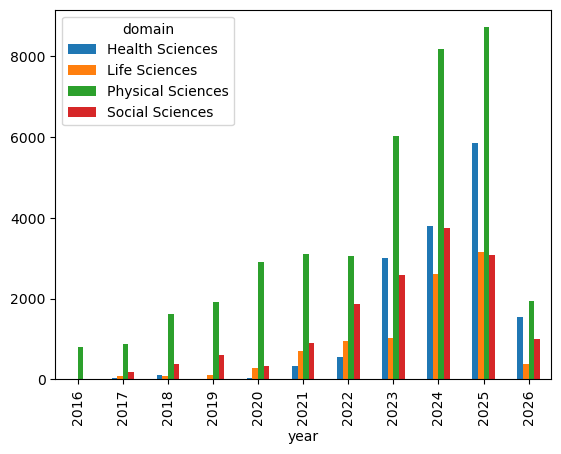

In [188]:
df[df["entity_type"] == "lm"].groupby(["year", "domain"], observed=True).size().unstack("domain").plot.bar()

In [189]:
df[df["entity_type"] == "lm"].groupby(["year", "domain"], observed=True)["score"].mean().unstack("domain").style.background_gradient(axis=None)

domain,Health Sciences,Life Sciences,Physical Sciences,Social Sciences
year,,,,
2016,-0.057451,0.055822,-0.032590,0.016959
2017,-0.023918,-0.015299,-0.026490,-0.012725
2018,-0.011129,-0.019321,-0.024422,0.007539
2019,-0.017676,-0.023939,-0.013923,0.004746
2020,-0.033614,-0.032126,-0.014705,0.009555
2021,-0.000410,-0.025752,-0.016207,-0.017261
2022,0.013416,-0.026467,-0.012934,-0.000059
2023,-0.006692,-0.020925,-0.007002,-0.002852
2024,-0.000127,-0.013844,-0.010534,-0.007323


<Axes: xlabel='entity_lower'>

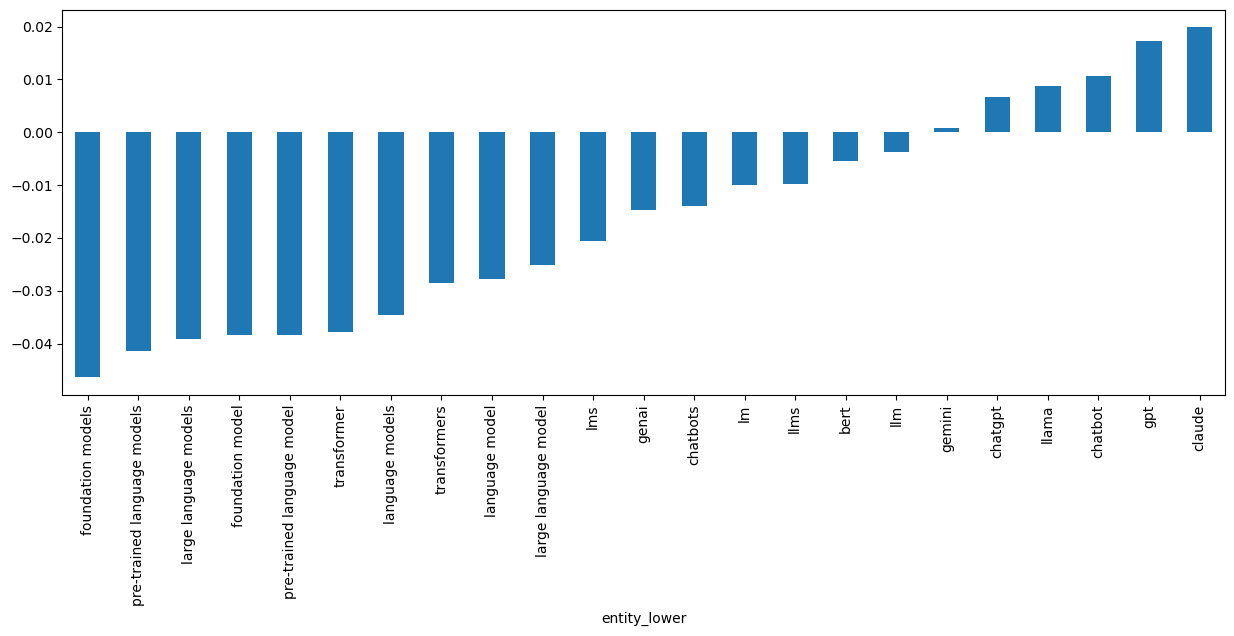

In [190]:
(df[df["entity_type"] == "lm"]
    .groupby("entity_lower", observed=True)["score"]
    .mean()
    .sort_values()
    .plot.bar(figsize=(15,5))
)

<Axes: xlabel='entity_lower'>

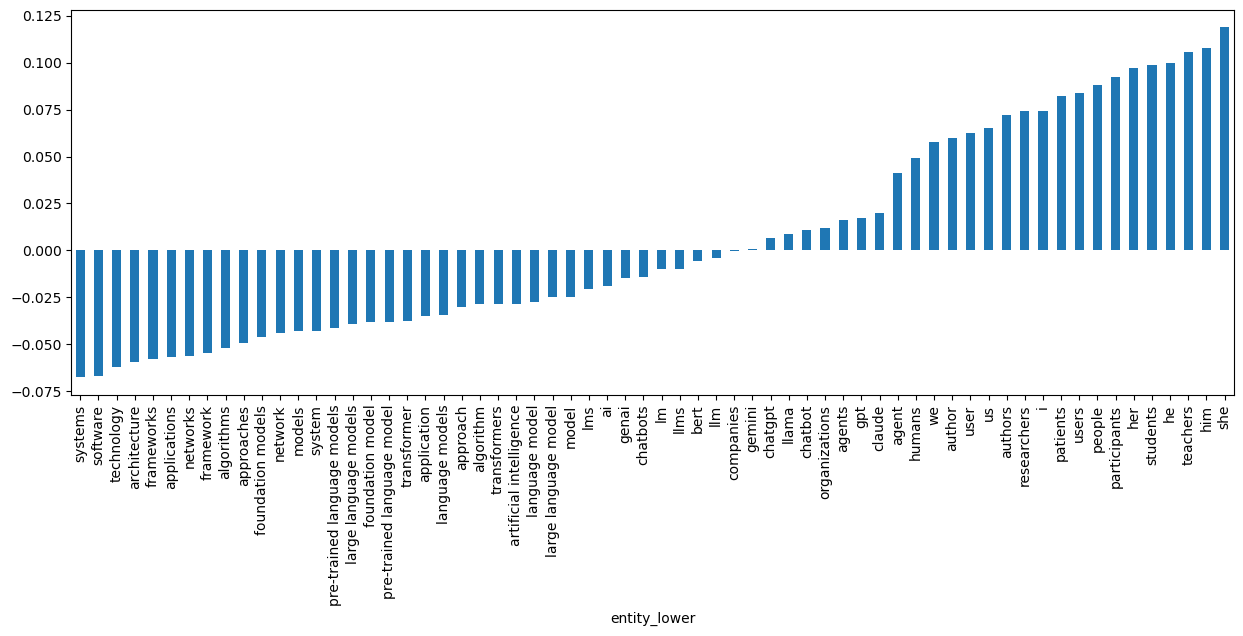

In [191]:
(df.groupby("entity_lower", observed=True)["score"]
    .mean()
    .sort_values()
    .plot.bar(figsize=(15,5))
)

<Axes: xlabel='year'>

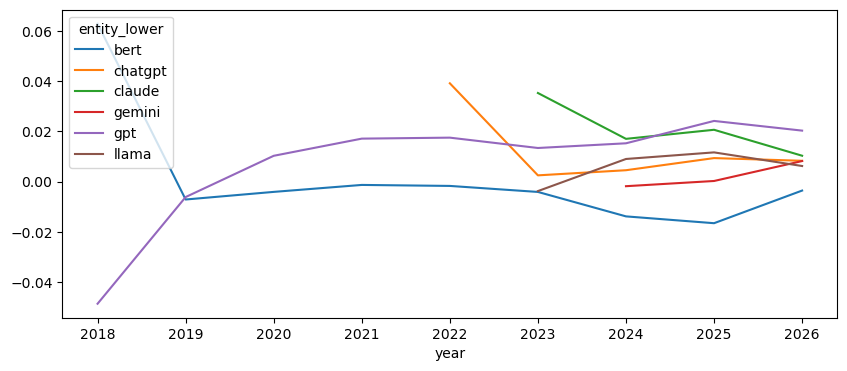

In [192]:
propn_lms = "bert claude llama gemini gpt chatgpt".split()
(df[df["entity_lower"].isin(propn_lms)]
    .groupby(["entity_lower", "year"], observed=True)["score"]
    .mean()
    .unstack("entity_lower")
    .plot(figsize=(10,4))
)

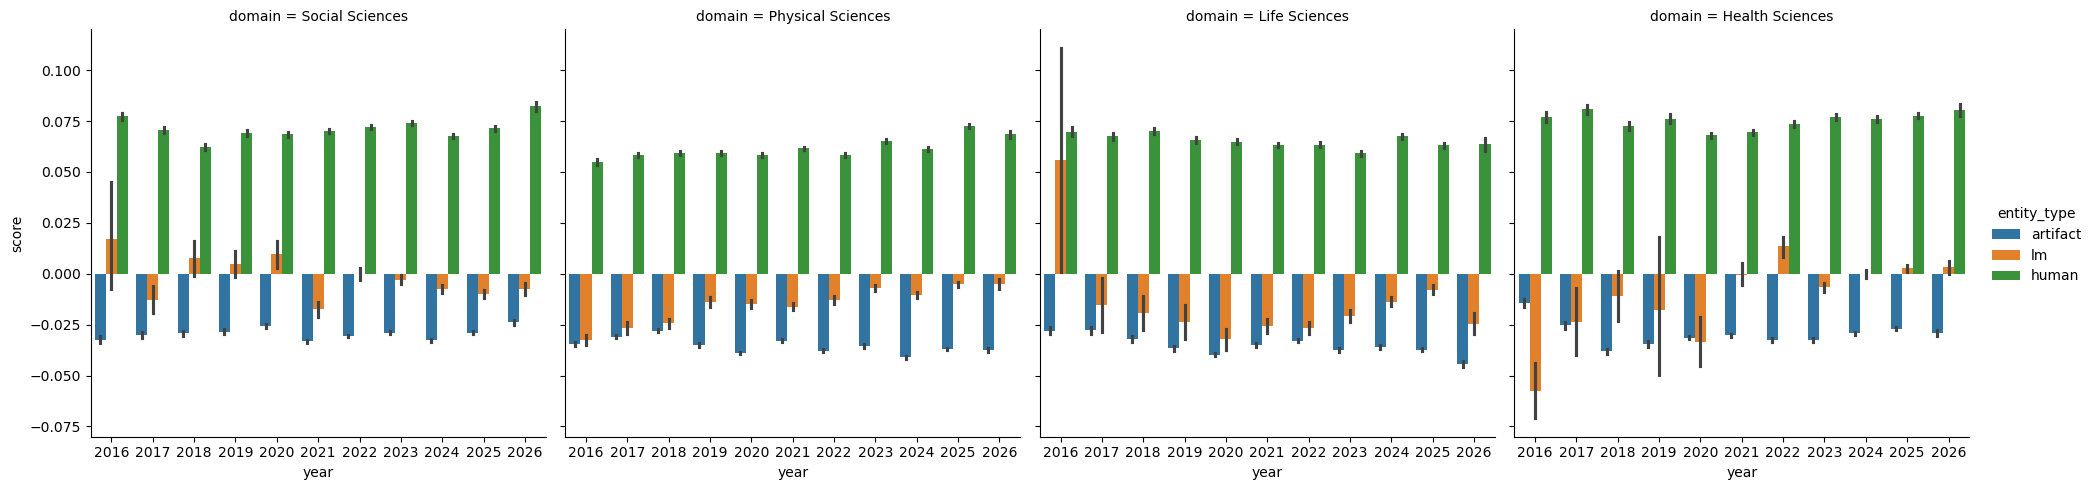

In [197]:
sns.catplot(
    data=df, x='year', y='score', hue='entity_type', col='domain',
    kind='bar', estimator='mean',
    order=sorted(df['year'].unique())
)
plt.show()

<Axes: xlabel='year'>

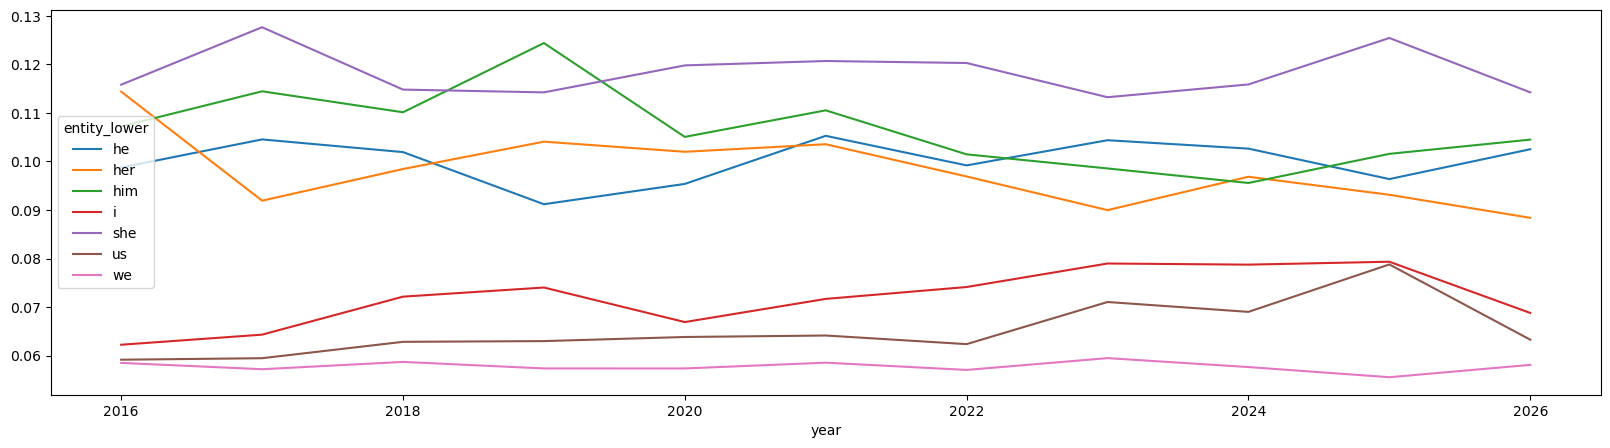

In [194]:
(df[df
    ["entity_lower"].isin(set(("he", "her", "him", "i", "she", "us", "we")))]
    .groupby(["entity_lower", "year"], observed=True)["score"]
    .mean()
    .unstack("entity_lower")
    .plot(figsize=(20,5))
)

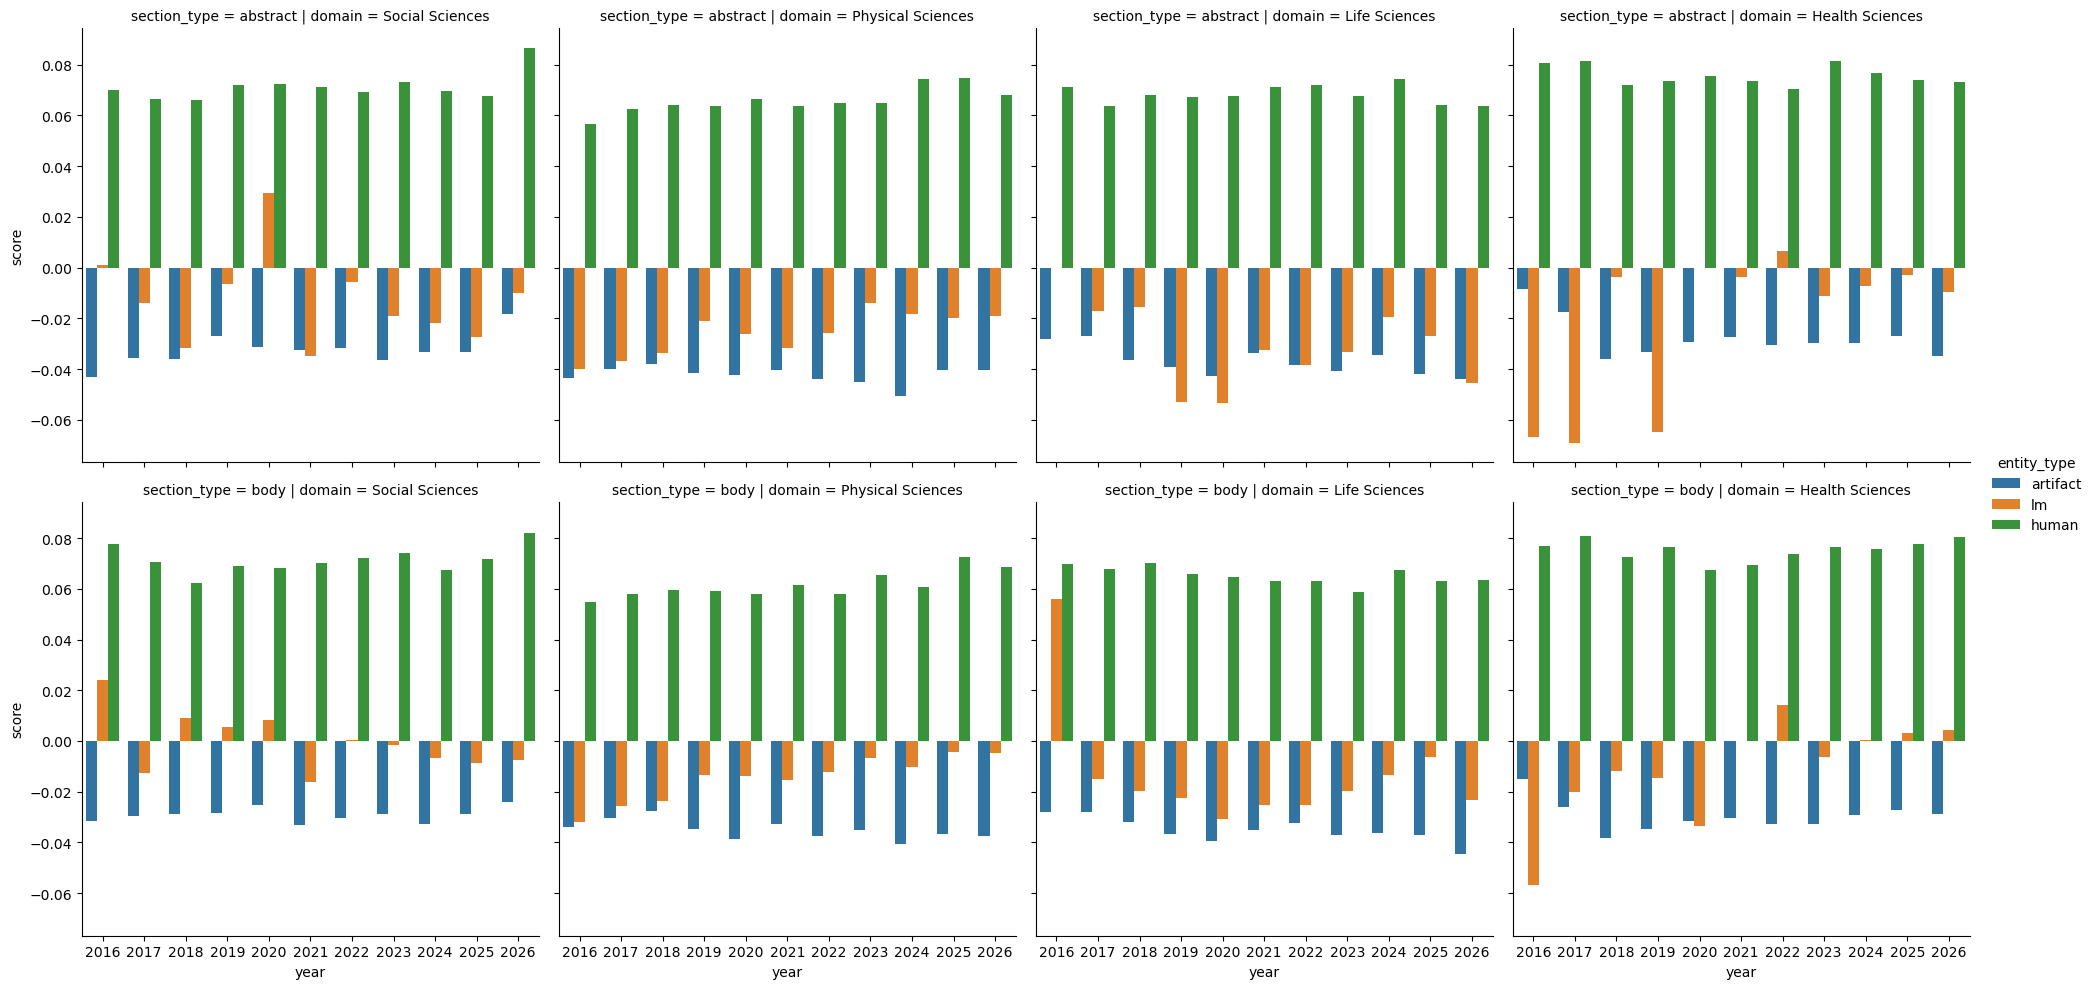

In [195]:
sns.catplot(
    data=df, x='year', y='score', hue='entity_type', col='domain', row="section_type",
    kind='bar', estimator='mean', errorbar=None,
    order=sorted(df['year'].unique())
)
plt.show()

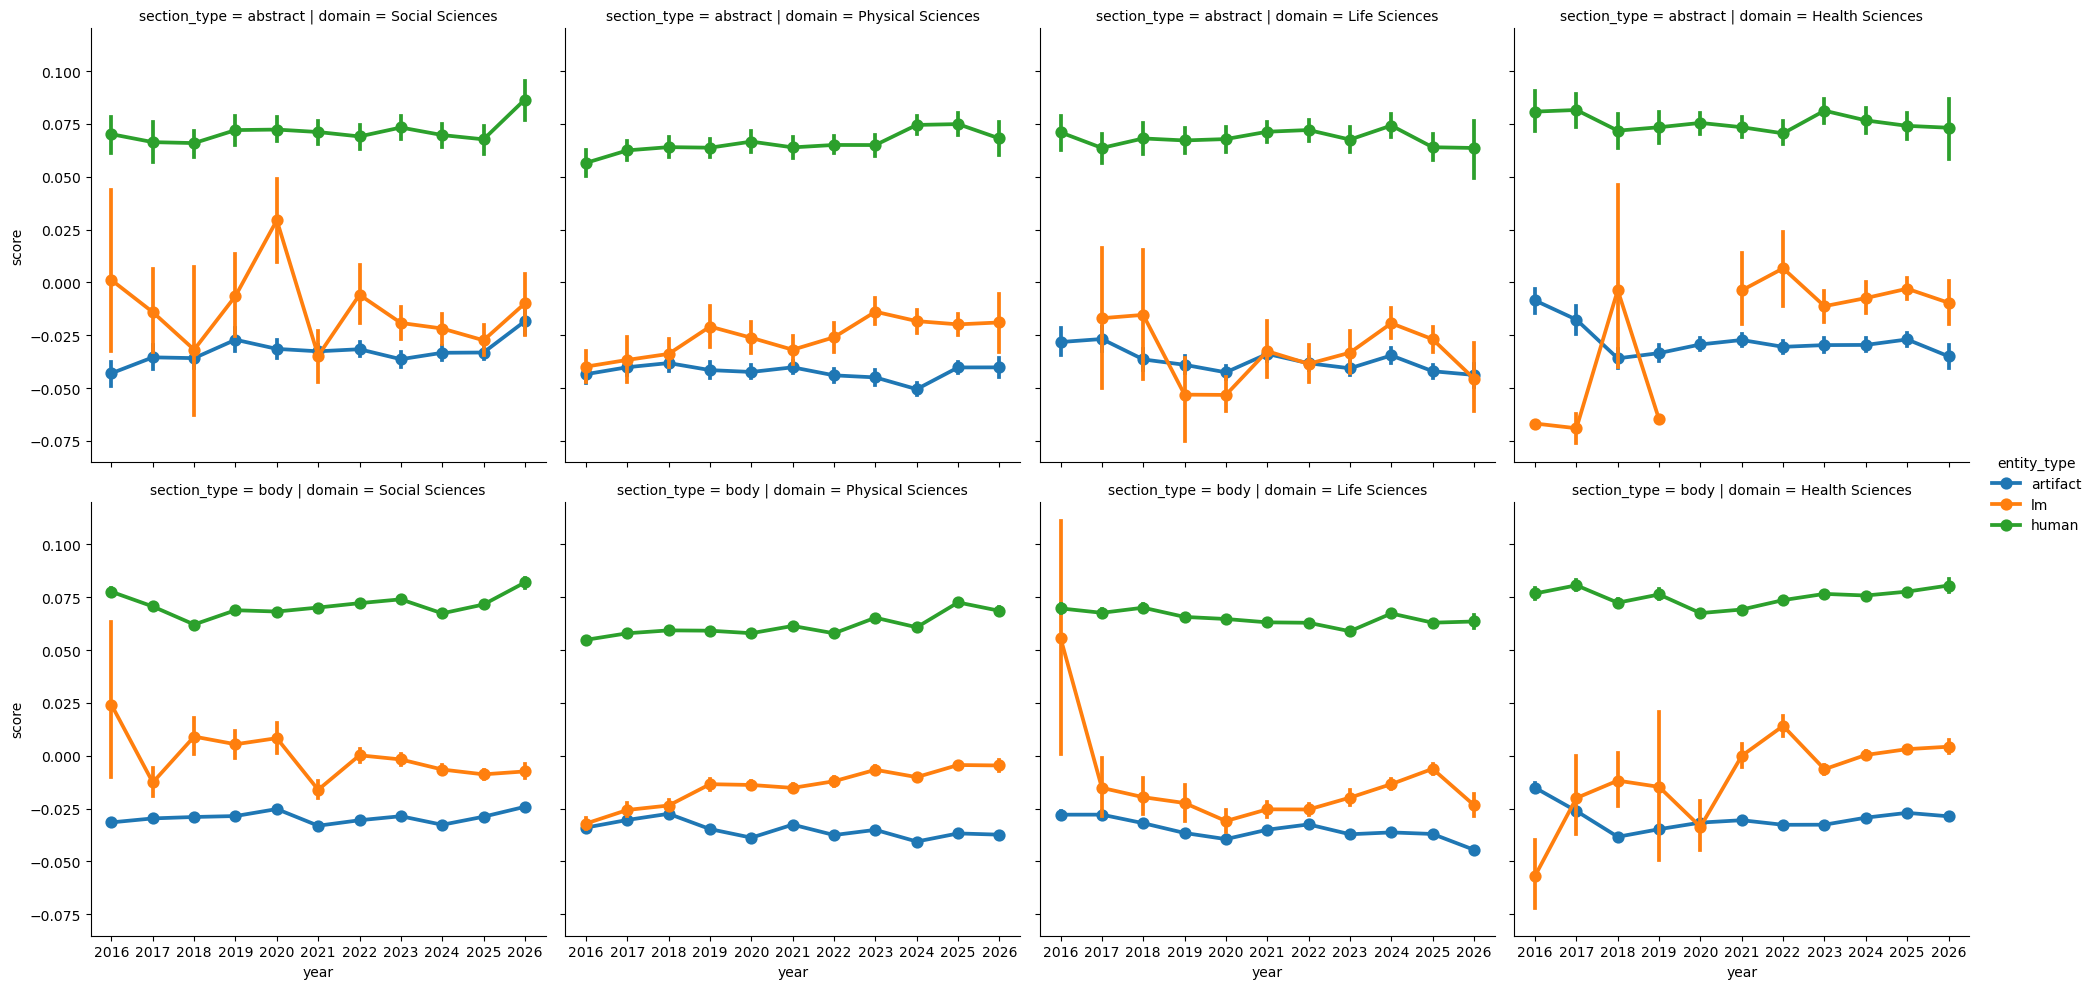

In [196]:
sns.catplot(
    data=df, x='year', y='score', hue='entity_type', col='domain', row="section_type",
    kind='point', estimator='mean',
    order=sorted(df['year'].unique())
)
plt.show()

In [208]:
doc_meta = df.groupby("paper_id").agg(
    year=("year", "first"),
    domain=("domain", "first"),
    has_abstract=("section_type", lambda x: (x == "abstract").any()),
    has_body=("section_type", lambda x: (x == "body").any()),
    contains_lm=("entity_type", lambda x: (x == "lm").any()),
    contains_artifact=("entity_type", lambda x: (x == "artifact").any()),
    contains_human=("entity_type", lambda x: (x == "human").any())
)

In [209]:
doc_meta.has_abstract.value_counts()

has_abstract
True     4644
False     277
Name: count, dtype: int64

In [210]:
doc_meta.has_body.value_counts()

has_body
True     4891
False      30
Name: count, dtype: int64

In [211]:
ids_to_keep = (doc_meta[(doc_meta["has_abstract"] == True) & (doc_meta["has_body"] == True) & (doc_meta["contains_lm"] == True)]).index

In [212]:
doc_meta_paired = (doc_meta.loc[ids_to_keep]).copy()

In [213]:
pd.crosstab(doc_meta_paired.year, doc_meta_paired.domain).style.background_gradient(axis=None)

domain,Health Sciences,Life Sciences,Physical Sciences,Social Sciences
year,,,,
2016,1,2,31,6
2017,3,6,51,8
2018,4,5,64,25
2019,5,9,61,25
2020,7,20,71,20
2021,20,23,72,59
2022,24,43,78,58
2023,48,43,82,66
2024,66,67,100,101


In [214]:
doc_meta_paired

,year,domain,has_abstract,has_body,contains_lm,contains_artifact,contains_human
paper_id,,,,,,,
W1585628326,2021,Physical Sciences,True,True,True,True,True
W2126793110,2018,Physical Sciences,True,True,True,True,True
W2144158482,2018,Physical Sciences,True,True,True,True,True
W2148798929,2018,Physical Sciences,True,True,True,True,True
W2210838531,2016,Physical Sciences,True,True,True,True,True
...,...,...,...,...,...,...,...
W7136068103,2026,Physical Sciences,True,True,True,True,True
W7136089029,2026,Physical Sciences,True,True,True,True,True
W7138989979,2026,Physical Sciences,True,True,True,True,True


In [215]:
paired = df[df["paper_id"].isin(doc_meta_paired.index)]
paired.info()

<class 'pandas.core.frame.DataFrame'>
Index: 481056 entries, 328 to 1057409
Data columns (total 32 columns):
 #   Column                   Non-Null Count   Dtype   
---  ------                   --------------   -----   
 0   paper_id                 481056 non-null  object  
 1   year                     481056 non-null  int64   
 2   domain                   481056 non-null  object  
 3   source_file              481056 non-null  object  
 4   global_i                 481056 non-null  int64   
 5   sentence_index           481056 non-null  int64   
 6   section                  453411 non-null  object  
 7   section_type             481056 non-null  object  
 8   paragraph_index          481056 non-null  int64   
 9   sent_id                  481056 non-null  int64   
 10  match_id                 481056 non-null  int64   
 11  sentence                 481056 non-null  object  
 12  masked_sentence_minimal  481056 non-null  object  
 13  masked_sentence_chunk    481056 non-null  obje

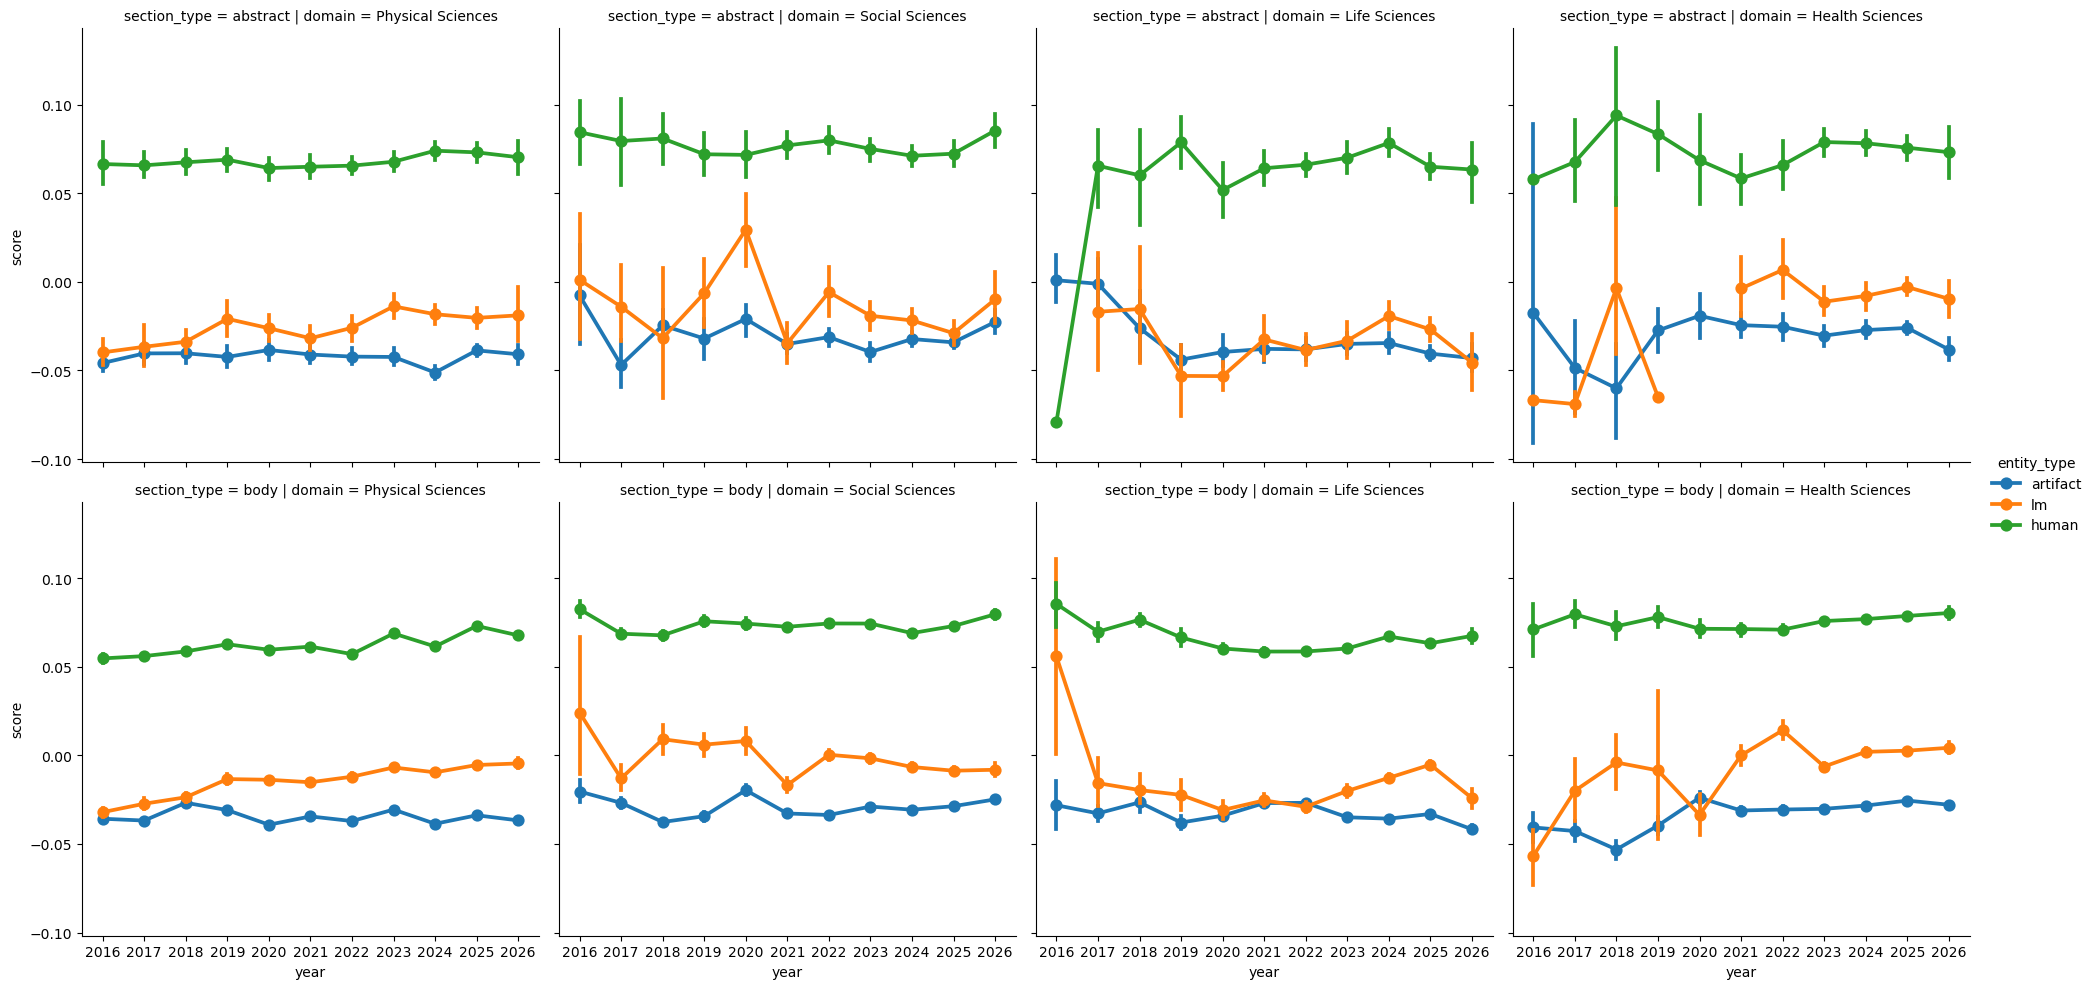

In [218]:
sns.catplot(
    data=paired, x='year', y='score', hue='entity_type', col='domain', row="section_type",
    kind='point', estimator='mean',
    order=sorted(paired['year'].unique())
)
plt.show()

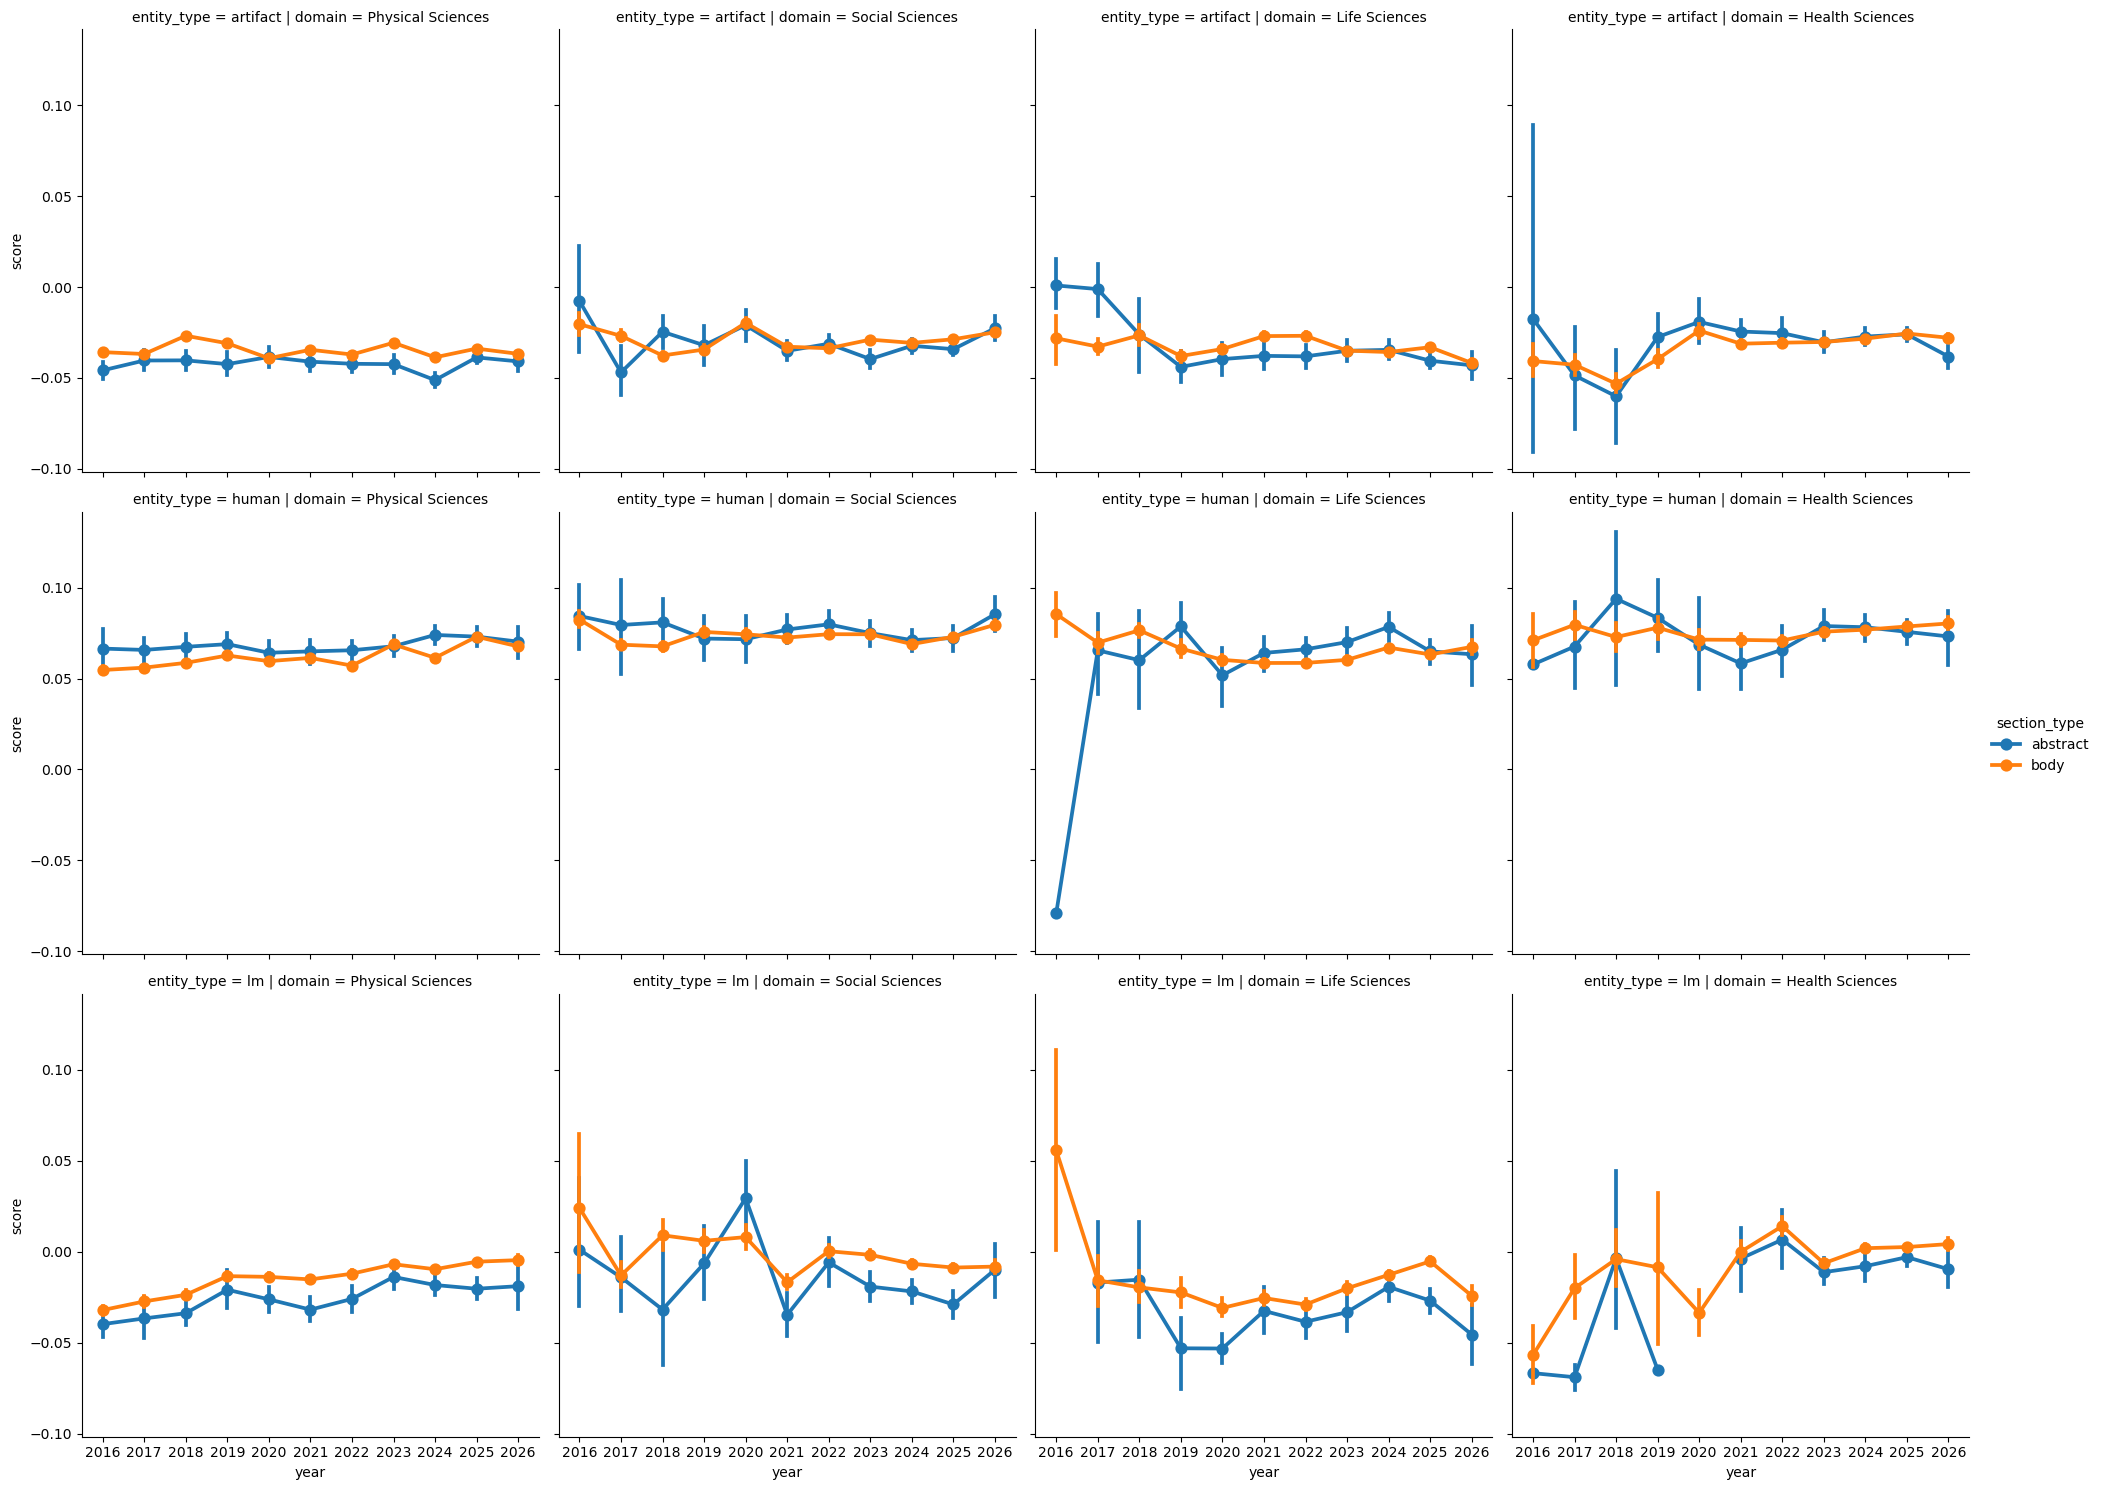

In [220]:
sns.catplot(
    data=paired, x='year', y='score', hue='section_type', col='domain', row="entity_type",
    kind='point', estimator='mean',
    order=sorted(paired['year'].unique())
)
plt.show()